**Отчет по лабораторной работе №2:**
**Классификация. Нейронные сети**

Дисциплина: Системы искусственного интеллекта и машинное обучение
Тема: Классификация и нейронные сети (Scikit-Learn, TensorFlow, TensorBoard)
Вариант: Датасет для класификации по выданным заёмам (clientes.csv)

Работу выполнила Жукова Е.И. студент группы АП-326

1. Введение

Цель работы: изучение методов классификации данных, реализованные в библиотеке Scikit-Learn, а также ознакомление с нейронными сетями с использованием библиотек TensorFlow и TensorBoard. 

Постановка задачи:

1. Необходимо выбрать и подготовить датасет для классификации, затем построить классификационные модели с помощью пяти методов:

- Наивный Байесовский классификатор (GaussianNB, MultinomialNB, ComplementNB, BernoulliNB);

- Деревья решений (Decision Tree);

- Линейный дискриминантный анализ (Linear Discriminant Analysis);

- Метод опорных векторов (Support Vector Machines);

- Метод ближайших соседей (k-Nearest Neighbors);

2. Затем сравните качество работы классификаторов с помощью следующих метрик:

- Accuracy (точность),

- Precision (доля правильно классифицированных положительных примеров),

- Recall (чувствительность, доля верно найденных положительных примеров),

- F1-Score (среднее гармоническое precision и recall),

- Площадь под кривой ROC (AUC-ROC).

3. Настройте гиперпараметры каждого метода и проведите исследование влияния различных параметров на качество классификации.

4. Реализуйте и протестируйте нейронную сеть на TensorFlow, исследуйте эффект настройки гиперпараметров и визуализируйте процесс обучения с помощью инструмента TensorBoard.

2. Выбор и подготовка датасета

В качестве исходного датасета используется файл clientes.csv, содержащий информацию о клиентах финансовой организации. Данные предназначены для прогнозирования результата рассмотрения заявки на кредит исходя из характеристики клиентов: пол, семейное положение, количество иждивенцев, образование, занятость, доход клиента и супруга, сумму и срок кредита, кредитную историю и расположение недвижимости.

Целевой переменной является aprovacao_emprestimo — результат рассмотрения кредитной заявки:
- Y — кредит одобрен (422 клиента);
- N — кредит не одобрен (192 клиента).

Импорт библиотек

In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split

from sklearn.preprocessing import (
    OneHotEncoder,
    StandardScaler,
    MinMaxScaler
)

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.impute import SimpleImputer

Загрузка датасета и проверка строк

In [2]:
df = pd.read_csv("clientes.csv")

df.head()

,cod_cliente,sexo,estado_civil,dependentes,educacao,empregado,renda,renda_conjuge,emprestimo,prestacao_mensal,historico_credito,imovel,aprovacao_emprestimo
0,LP001002,Male,No,0,Graduate,No,5849,0,NaN,360.0,1.0,Urban,Y
1,LP001003,Male,Yes,1,Graduate,No,4583,1508,128.0,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0,66.0,360.0,1.0,Urban,Y
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358,120.0,360.0,1.0,Urban,Y
4,LP001008,Male,No,0,Graduate,No,6000,0,141.0,360.0,1.0,Urban,Y


Первичный анализ датасета, смотрим общую информацию, названия столбцов, статистическая информация

In [3]:
df.shape

df.info()

df.columns

df.describe(include="all").T

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 614 entries, 0 to 613
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   cod_cliente           614 non-null    object 
 1   sexo                  601 non-null    object 
 2   estado_civil          611 non-null    object 
 3   dependentes           599 non-null    object 
 4   educacao              614 non-null    object 
 5   empregado             582 non-null    object 
 6   renda                 614 non-null    int64  
 7   renda_conjuge         614 non-null    object 
 8   emprestimo            592 non-null    float64
 9   prestacao_mensal      600 non-null    float64
 10  historico_credito     564 non-null    float64
 11  imovel                614 non-null    object 
 12  aprovacao_emprestimo  614 non-null    object 
dtypes: float64(3), int64(1), object(9)
memory usage: 62.5+ KB


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
cod_cliente,614,614,LP002990,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
sexo,601,2,Male,489,NaN,NaN,NaN,NaN,NaN,NaN,NaN
estado_civil,611,2,Yes,398,NaN,NaN,NaN,NaN,NaN,NaN,NaN
dependentes,599,4,0,345,NaN,NaN,NaN,NaN,NaN,NaN,NaN
educacao,614,2,Graduate,480,NaN,NaN,NaN,NaN,NaN,NaN,NaN
empregado,582,2,No,500,NaN,NaN,NaN,NaN,NaN,NaN,NaN
renda,614.0,NaN,NaN,NaN,5403.459283,6109.041673,150.0,2877.5,3812.5,5795.0,81000.0
renda_conjuge,614,287,0,273,NaN,NaN,NaN,NaN,NaN,NaN,NaN
emprestimo,592.0,NaN,NaN,NaN,146.412162,85.587325,9.0,100.0,128.0,168.0,700.0
prestacao_mensal,600.0,NaN,NaN,NaN,342.0,65.12041,12.0,360.0,360.0,360.0,480.0


Проверка пропусков

In [4]:
df.isnull().sum()

missing = pd.DataFrame({
    "Количество пропусков": df.isnull().sum(),
    "Процент пропусков": df.isnull().mean() * 100
})

missing

,Количество пропусков,Процент пропусков
cod_cliente,0,0.000000
sexo,13,2.117264
estado_civil,3,0.488599
dependentes,15,2.442997
educacao,0,0.000000
empregado,32,5.211726
renda,0,0.000000
renda_conjuge,0,0.000000
emprestimo,22,3.583062
prestacao_mensal,14,2.280130


Проверка дубликатов

In [5]:
df.duplicated().sum()

df = df.drop_duplicates()

Анализ уникальных значений перед обработкой категориальных признаков

In [6]:
for column in df.columns:
    print(f"\n{column}:")
    print(df[column].value_counts(dropna=False))

categorical_columns = [
    "sexo",
    "estado_civil",
    "dependentes",
    "educacao",
    "empregado",
    "historico_credito",
    "imovel",
    "aprovacao_emprestimo"
]

for column in categorical_columns:
    print(f"\n{column}")
    print(df[column].value_counts(dropna=False))


cod_cliente:
cod_cliente
LP002990    1
LP001002    1
LP001003    1
LP001005    1
LP001006    1
           ..
LP001020    1
LP001024    1
LP001027    1
LP001028    1
LP001029    1
Name: count, Length: 614, dtype: int64

sexo:
sexo
Male      489
Female    112
NaN        13
Name: count, dtype: int64

estado_civil:
estado_civil
Yes    398
No     213
NaN      3
Name: count, dtype: int64

dependentes:
dependentes
0      345
1      102
2      101
3+      51
NaN     15
Name: count, dtype: int64

educacao:
educacao
Graduate        480
Not Graduate    134
Name: count, dtype: int64

empregado:
empregado
No     500
Yes     82
NaN     32
Name: count, dtype: int64

renda:
renda
2500     9
2600     6
4583     6
6000     6
5000     5
        ..
11500    1
2708     1
2132     1
3366     1
1299     1
Name: count, Length: 505, dtype: int64

renda_conjuge:
renda_conjuge
0       273
1666      5
2500      5
2083      5
5625      3
       ... 
2302      1
997       1
3541      1
3263      1
4301      1
Name

Удаление идентификатора клиента и исправление искаженных десятичных значений

In [7]:
df = df.drop(columns=["cod_cliente"])

df["renda_conjuge"] = df["renda_conjuge"].replace({
    "9.857.999.878": "985.7999878",
    "1.612.000.084": "1612.000084"
})

df["renda_conjuge"] = pd.to_numeric(
    df["renda_conjuge"],
    errors="coerce"
)

df["renda_conjuge"].dtype

df["renda_conjuge"].isnull().sum()

np.int64(0)

In [8]:
df["dependentes"] = df["dependentes"].replace("3+", "3")

df["dependentes"] = pd.to_numeric(
    df["dependentes"],
    errors="coerce"
)

df["dependentes"].value_counts(dropna=False)

dependentes
0.0    345
1.0    102
2.0    101
3.0     51
NaN     15
Name: count, dtype: int64

Координирование целефой переменной (Y в 1 N в 0)

In [9]:
df["aprovacao_emprestimo"] = df["aprovacao_emprestimo"].map({
    "Y": 1,
    "N": 0
})

df["aprovacao_emprestimo"].value_counts()

df["aprovacao_emprestimo"].value_counts(normalize=True)

aprovacao_emprestimo
1    0.687296
0    0.312704
Name: proportion, dtype: float64

Проверка типов после очистки и числовых переменных

In [10]:
df.info()

numeric_features = [
    "dependentes",
    "renda",
    "renda_conjuge",
    "emprestimo",
    "prestacao_mensal"
]

categorical_features = [
    "sexo",
    "estado_civil",
    "educacao",
    "empregado",
    "historico_credito",
    "imovel"
]

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 614 entries, 0 to 613
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   sexo                  601 non-null    object 
 1   estado_civil          611 non-null    object 
 2   dependentes           599 non-null    float64
 3   educacao              614 non-null    object 
 4   empregado             582 non-null    object 
 5   renda                 614 non-null    int64  
 6   renda_conjuge         614 non-null    float64
 7   emprestimo            592 non-null    float64
 8   prestacao_mensal      600 non-null    float64
 9   historico_credito     564 non-null    float64
 10  imovel                614 non-null    object 
 11  aprovacao_emprestimo  614 non-null    int64  
dtypes: float64(5), int64(2), object(5)
memory usage: 57.7+ KB


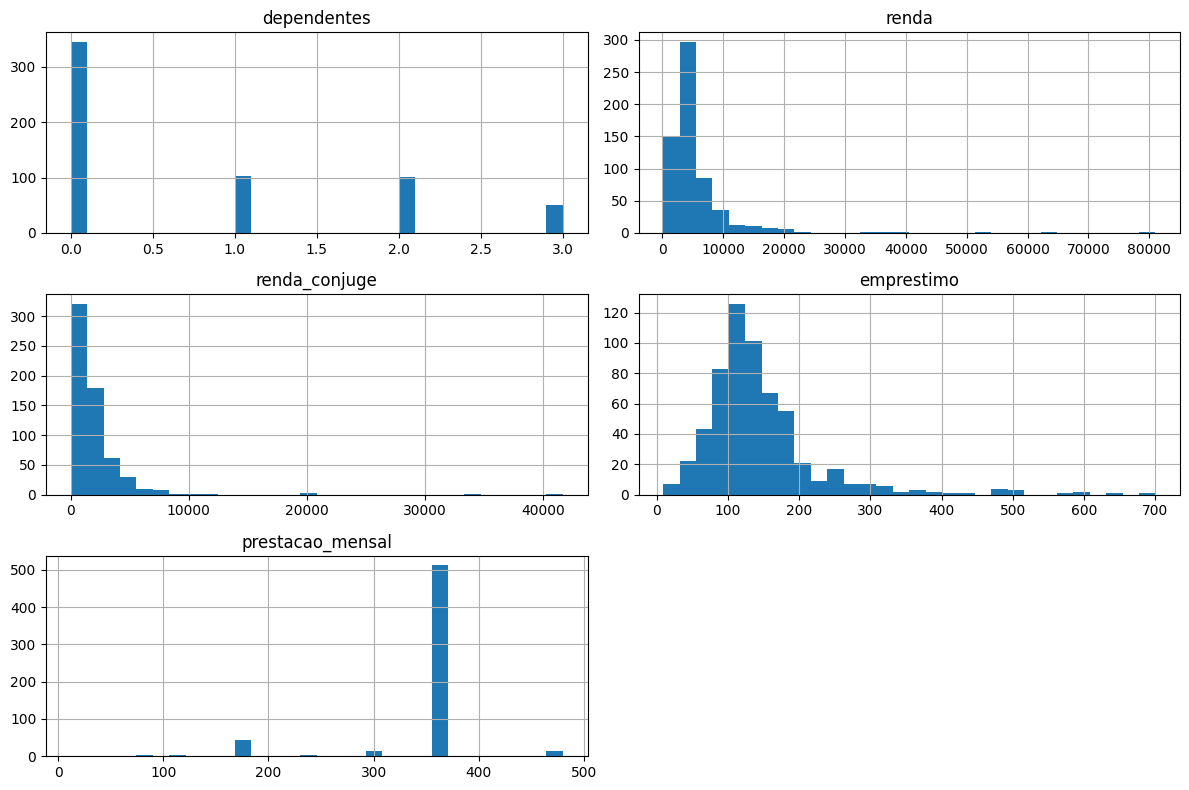

In [11]:
df[numeric_features].describe()

df[numeric_features].hist(
    figsize=(12, 8),
    bins=30
)

plt.tight_layout()
plt.show()

Большинство числовых признаков имеют несимметричные распределения с положительной асимметрией. Для доходов и суммы кредита характерны правосторонние хвосты и выбросы. Распределения существенно отличаются от нормального.

Отделение признаков от целевой переменной

In [12]:
X = df.drop(columns=["aprovacao_emprestimo"])
y = df["aprovacao_emprestimo"]

X.head()
y.head()

0    1
1    0
2    1
3    1
4    1
Name: aprovacao_emprestimo, dtype: int64

3. Разделение выборки

Разделение на train и test (80 на 20)

In [13]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

print("Обучающая выборка:")
print(y_train.value_counts(normalize=True))

print("\nТестовая выборка:")
print(y_test.value_counts(normalize=True))

X_train: (491, 11)
X_test: (123, 11)
y_train: (491,)
y_test: (123,)
Обучающая выборка:
aprovacao_emprestimo
1    0.686354
0    0.313646
Name: proportion, dtype: float64

Тестовая выборка:
aprovacao_emprestimo
1    0.691057
0    0.308943
Name: proportion, dtype: float64


Заполнение пропусков с помощью медианы для числовых признаков и среднего значения для категориальных

In [14]:
numeric_imputer = SimpleImputer(strategy="median")

categorical_imputer = SimpleImputer(strategy="most_frequent")

Стандартизация числовых признаков

In [15]:
StandardScaler()

numeric_transformer_standard = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]
)

Обработка категориальных признаков. Заменяем пропуски модой, после чего категории кодируем с помощью One-Hot Encoding.

In [16]:
categorical_transformer = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="most_frequent")
        ),
        (
            "onehot",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False
            )
        )
    ]
)

Общий preprocessing для стандартизированных данных, обучаем преобразавания на train, применяем на test

In [17]:
preprocessor_standard = ColumnTransformer(
    transformers=[
        (
            "num",
            numeric_transformer_standard,
            numeric_features
        ),
        (
            "cat",
            categorical_transformer,
            categorical_features
        )
    ]
)

X_train_standard = preprocessor_standard.fit_transform(X_train)

X_test_standard = preprocessor_standard.transform(X_test)

print(X_train_standard.shape)
print(X_test_standard.shape)

(491, 18)
(123, 18)


Преобразованные признаки

In [18]:
feature_names = preprocessor_standard.get_feature_names_out()

X_train_standard_df = pd.DataFrame(
    X_train_standard,
    columns=feature_names,
    index=X_train.index
)

X_test_standard_df = pd.DataFrame(
    X_test_standard,
    columns=feature_names,
    index=X_test.index
)

X_train_standard_df.head()

X_train_standard_df.isnull().sum().sum()

np.int64(0)

Нормализованная версия данных. MultinomialNB и ComplementNB требуют неотрицательных значений. После StandardScaler появляются отрицательные числа.

In [19]:
numeric_transformer_minmax = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="median")
        ),
        (
            "scaler",
            MinMaxScaler()
        )
    ]
)

preprocessor_minmax = ColumnTransformer(
    transformers=[
        (
            "num",
            numeric_transformer_minmax,
            numeric_features
        ),
        (
            "cat",
            categorical_transformer,
            categorical_features
        )
    ]
)

X_train_minmax = preprocessor_minmax.fit_transform(X_train)
X_test_minmax = preprocessor_minmax.transform(X_test)

print("Минимум:", X_train_minmax.min())
print("Максимум:", X_train_minmax.max())

Минимум: 0.0
Максимум: 1.0000000000000002


Проверка обработанных данных

In [20]:
print("Пропуски StandardScaler:",
      np.isnan(X_train_standard).sum())

print("Пропуски MinMaxScaler:",
      np.isnan(X_train_minmax).sum())

print("Размер StandardScaler:",
      X_train_standard.shape)

print("Размер MinMaxScaler:",
      X_train_minmax.shape)

Пропуски StandardScaler: 0
Пропуски MinMaxScaler: 0
Размер StandardScaler: (491, 18)
Размер MinMaxScaler: (491, 18)


4. Методы классификации

Импорт классификаторов и проверка работы моделей

In [21]:
from sklearn.naive_bayes import (
    GaussianNB,
    MultinomialNB,
    ComplementNB,
    BernoulliNB
)

from sklearn.tree import DecisionTreeClassifier
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier

In [22]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

Функция для оценки модели (чтобы не повторять один и тот же код для каждой)

Что делает:
1. обучает модель;
2. делает прогноз;
3. получает probability/decision score для ROC-AUC;
4. рассчитывает все необходимые метрики.

In [23]:
def evaluate_model(model, X_train, X_test, y_train, y_test):
    
    # Обучение
    model.fit(X_train, y_train)
    
    # Предсказание классов
    y_pred = model.predict(X_test)
    
    # Вероятности положительного класса для ROC-AUC
    if hasattr(model, "predict_proba"):
        y_score = model.predict_proba(X_test)[:, 1]
        
    elif hasattr(model, "decision_function"):
        y_score = model.decision_function(X_test)
        
    else:
        y_score = y_pred
    
    # Метрики
    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred, zero_division=0)
    recall = recall_score(y_test, y_pred, zero_division=0)
    f1 = f1_score(y_test, y_pred, zero_division=0)
    roc_auc = roc_auc_score(y_test, y_score)
    
    print("Accuracy:", round(accuracy, 4))
    print("Precision:", round(precision, 4))
    print("Recall:", round(recall, 4))
    print("F1-score:", round(f1, 4))
    print("ROC-AUC:", round(roc_auc, 4))
    
    print("\nConfusion matrix:")
    print(confusion_matrix(y_test, y_pred))
    
    print("\nClassification report:")
    print(classification_report(y_test, y_pred, zero_division=0))
    
    return {
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1": f1,
        "ROC-AUC": roc_auc
    }

#Словарь для сохранения результатов
results = {}

Gaussian Naive Bayes - вероятностный классификатор, основанный на теореме Байеса. Предполагает независимость признаков и их нормальное распределение внутри каждого класса. Подходит для непрерывных числовых данных.

In [24]:
gaussian_nb = GaussianNB()

results["GaussianNB"] = evaluate_model(
    gaussian_nb,
    X_train_standard,
    X_test_standard,
    y_train,
    y_test
)

Accuracy: 0.8537
Precision: 0.8384
Recall: 0.9765
F1-score: 0.9022
ROC-AUC: 0.8037

Confusion matrix:
[[22 16]
 [ 2 83]]

Classification report:
              precision    recall  f1-score   support

           0       0.92      0.58      0.71        38
           1       0.84      0.98      0.90        85

    accuracy                           0.85       123
   macro avg       0.88      0.78      0.81       123
weighted avg       0.86      0.85      0.84       123



Multinomial Naive Bayes - использует мультиномиальное распределение признаков. Подходит для дискретных неотрицательных данных, особенно для классификации текстов по частотам слов.

In [25]:
multinomial_nb = MultinomialNB()

results["MultinomialNB"] = evaluate_model(
    multinomial_nb,
    X_train_minmax,
    X_test_minmax,
    y_train,
    y_test
)

Accuracy: 0.8537
Precision: 0.8317
Recall: 0.9882
F1-score: 0.9032
ROC-AUC: 0.8542

Confusion matrix:
[[21 17]
 [ 1 84]]

Classification report:
              precision    recall  f1-score   support

           0       0.95      0.55      0.70        38
           1       0.83      0.99      0.90        85

    accuracy                           0.85       123
   macro avg       0.89      0.77      0.80       123
weighted avg       0.87      0.85      0.84       123



Complement Naive Bayes - модификация MultinomialNB, рассчитывающая веса признаков на основе данных остальных классов. Особенно эффективен при несбалансированных классах.

In [26]:
complement_nb = ComplementNB()

results["ComplementNB"] = evaluate_model(
    complement_nb,
    X_train_minmax,
    X_test_minmax,
    y_train,
    y_test
)

Accuracy: 0.8293
Precision: 0.8478
Recall: 0.9176
F1-score: 0.8814
ROC-AUC: 0.8542

Confusion matrix:
[[24 14]
 [ 7 78]]

Classification report:
              precision    recall  f1-score   support

           0       0.77      0.63      0.70        38
           1       0.85      0.92      0.88        85

    accuracy                           0.83       123
   macro avg       0.81      0.77      0.79       123
weighted avg       0.83      0.83      0.82       123



Bernoulli Naive Bayes - использует распределение Бернулли и работает с бинарными признаками (0 или 1), отражающими наличие или отсутствие определённой характеристики.

In [27]:
bernoulli_nb = BernoulliNB(
    binarize=0.5
)

results["BernoulliNB"] = evaluate_model(
    bernoulli_nb,
    X_train_minmax,
    X_test_minmax,
    y_train,
    y_test
)

Accuracy: 0.8537
Precision: 0.8384
Recall: 0.9765
F1-score: 0.9022
ROC-AUC: 0.8458

Confusion matrix:
[[22 16]
 [ 2 83]]

Classification report:
              precision    recall  f1-score   support

           0       0.92      0.58      0.71        38
           1       0.84      0.98      0.90        85

    accuracy                           0.85       123
   macro avg       0.88      0.78      0.81       123
weighted avg       0.86      0.85      0.84       123



Decision Tree - классифицирует объекты с помощью последовательных проверок условий по признакам. На каждом узле выбирается разделение, позволяющее лучше различать классы.

In [28]:
decision_tree = DecisionTreeClassifier(
    random_state=42
)

results["Decision Tree"] = evaluate_model(
    decision_tree,
    X_train_standard,
    X_test_standard,
    y_train,
    y_test
)

Accuracy: 0.748
Precision: 0.8214
Recall: 0.8118
F1-score: 0.8166
ROC-AUC: 0.7085

Confusion matrix:
[[23 15]
 [16 69]]

Classification report:
              precision    recall  f1-score   support

           0       0.59      0.61      0.60        38
           1       0.82      0.81      0.82        85

    accuracy                           0.75       123
   macro avg       0.71      0.71      0.71       123
weighted avg       0.75      0.75      0.75       123



Linear Discriminant Analysis - строит линейные границы между классами, предполагая нормальное распределение признаков внутри классов и одинаковые ковариационные матрицы.

In [29]:
lda = LinearDiscriminantAnalysis()

results["LDA"] = evaluate_model(
    lda,
    X_train_standard,
    X_test_standard,
    y_train,
    y_test
)

Accuracy: 0.8618
Precision: 0.84
Recall: 0.9882
F1-score: 0.9081
ROC-AUC: 0.8471

Confusion matrix:
[[22 16]
 [ 1 84]]

Classification report:
              precision    recall  f1-score   support

           0       0.96      0.58      0.72        38
           1       0.84      0.99      0.91        85

    accuracy                           0.86       123
   macro avg       0.90      0.78      0.81       123
weighted avg       0.88      0.86      0.85       123



Support Vector Machine - находит разделяющую границу с максимальным зазором между классами. С помощью ядерных функций позволяет строить нелинейные границы.

In [30]:
svm = SVC(
    kernel="rbf",
    probability=True,
    random_state=42
)

results["SVM"] = evaluate_model(
    svm,
    X_train_standard,
    X_test_standard,
    y_train,
    y_test
)

probability=True


Accuracy: 0.8455
Precision: 0.8235
Recall: 0.9882
F1-score: 0.8984
ROC-AUC: 0.8201

Confusion matrix:
[[20 18]
 [ 1 84]]

Classification report:
              precision    recall  f1-score   support

           0       0.95      0.53      0.68        38
           1       0.82      0.99      0.90        85

    accuracy                           0.85       123
   macro avg       0.89      0.76      0.79       123
weighted avg       0.86      0.85      0.83       123



k-Nearest Neighbors - определяет класс нового объекта по наиболее распространённому классу среди его k ближайших соседей в пространстве признаков.

In [31]:
knn = KNeighborsClassifier(
    n_neighbors=5
)

results["kNN"] = evaluate_model(
    knn,
    X_train_standard,
    X_test_standard,
    y_train,
    y_test
)

Accuracy: 0.8211
Precision: 0.8058
Recall: 0.9765
F1-score: 0.883
ROC-AUC: 0.7858

Confusion matrix:
[[18 20]
 [ 2 83]]

Classification report:
              precision    recall  f1-score   support

           0       0.90      0.47      0.62        38
           1       0.81      0.98      0.88        85

    accuracy                           0.82       123
   macro avg       0.85      0.73      0.75       123
weighted avg       0.83      0.82      0.80       123



Сводная таблица всех классификаторов

In [32]:
results_df = pd.DataFrame(results).T

results_df.round(4)

,Accuracy,Precision,Recall,F1,ROC-AUC
GaussianNB,0.8537,0.8384,0.9765,0.9022,0.8037
MultinomialNB,0.8537,0.8317,0.9882,0.9032,0.8542
ComplementNB,0.8293,0.8478,0.9176,0.8814,0.8542
BernoulliNB,0.8537,0.8384,0.9765,0.9022,0.8458
Decision Tree,0.7480,0.8214,0.8118,0.8166,0.7085
LDA,0.8618,0.8400,0.9882,0.9081,0.8471
SVM,0.8455,0.8235,0.9882,0.8984,0.8201
kNN,0.8211,0.8058,0.9765,0.8830,0.7858


Сравнение качества работы классификаторов с помощью метрик (Accuracy (точность), Precision (доля правильно классифицированных положительных примеров), Recall (чувствительность, доля верно найденных положительных примеров), F1-Score (среднее гармоническое precision и recall), Площадь под кривой ROC (AUC-ROC).)

Отсортируем модели по Accuracy

In [33]:
results_df.sort_values(
    by="Accuracy",
    ascending=False
).round(4)

,Accuracy,Precision,Recall,F1,ROC-AUC
LDA,0.8618,0.8400,0.9882,0.9081,0.8471
GaussianNB,0.8537,0.8384,0.9765,0.9022,0.8037
BernoulliNB,0.8537,0.8384,0.9765,0.9022,0.8458
MultinomialNB,0.8537,0.8317,0.9882,0.9032,0.8542
SVM,0.8455,0.8235,0.9882,0.8984,0.8201
ComplementNB,0.8293,0.8478,0.9176,0.8814,0.8542
kNN,0.8211,0.8058,0.9765,0.8830,0.7858
Decision Tree,0.7480,0.8214,0.8118,0.8166,0.7085


По F1

In [34]:
results_df.sort_values(
    by="F1",
    ascending=False
).round(4)

,Accuracy,Precision,Recall,F1,ROC-AUC
LDA,0.8618,0.8400,0.9882,0.9081,0.8471
MultinomialNB,0.8537,0.8317,0.9882,0.9032,0.8542
BernoulliNB,0.8537,0.8384,0.9765,0.9022,0.8458
GaussianNB,0.8537,0.8384,0.9765,0.9022,0.8037
SVM,0.8455,0.8235,0.9882,0.8984,0.8201
kNN,0.8211,0.8058,0.9765,0.8830,0.7858
ComplementNB,0.8293,0.8478,0.9176,0.8814,0.8542
Decision Tree,0.7480,0.8214,0.8118,0.8166,0.7085


По ROC-AUC

In [35]:
results_df.sort_values(
    by="ROC-AUC",
    ascending=False
).round(4)

,Accuracy,Precision,Recall,F1,ROC-AUC
MultinomialNB,0.8537,0.8317,0.9882,0.9032,0.8542
ComplementNB,0.8293,0.8478,0.9176,0.8814,0.8542
LDA,0.8618,0.8400,0.9882,0.9081,0.8471
BernoulliNB,0.8537,0.8384,0.9765,0.9022,0.8458
SVM,0.8455,0.8235,0.9882,0.8984,0.8201
GaussianNB,0.8537,0.8384,0.9765,0.9022,0.8037
kNN,0.8211,0.8058,0.9765,0.8830,0.7858
Decision Tree,0.7480,0.8214,0.8118,0.8166,0.7085


Сравнение метрик

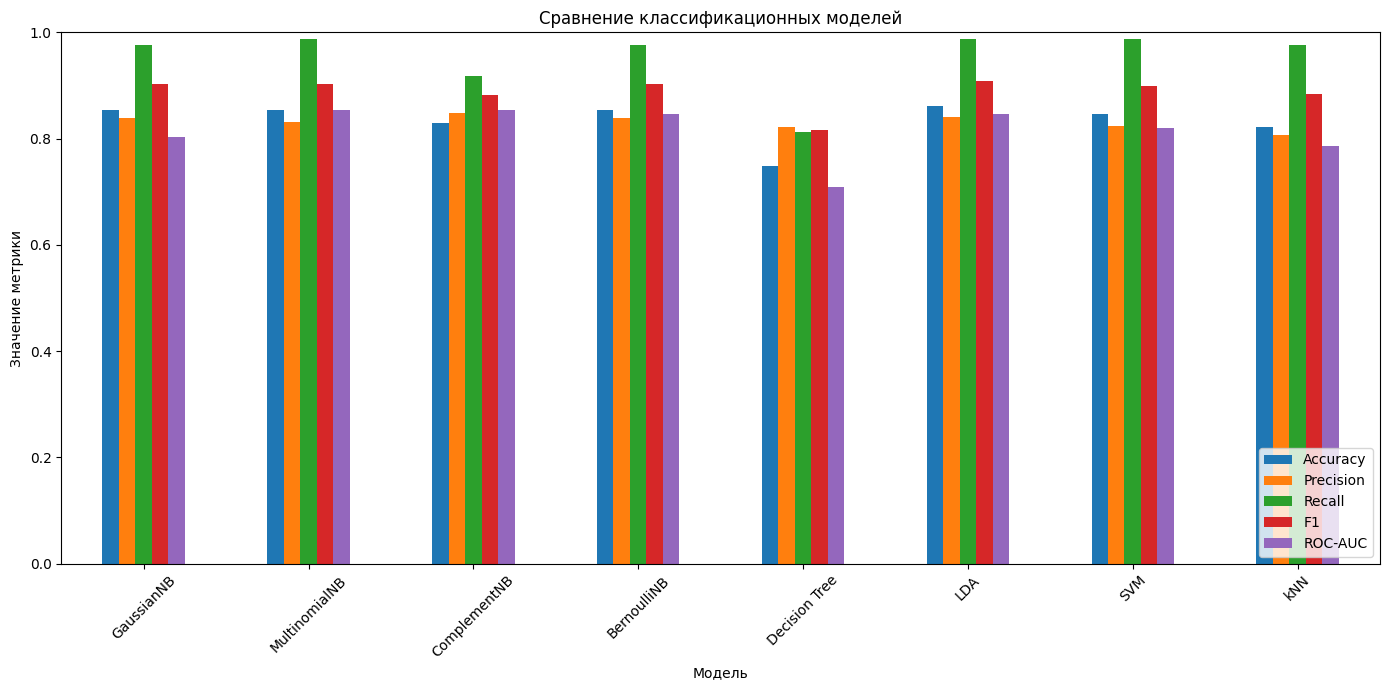

In [36]:
results_df.plot(
    kind="bar",
    figsize=(14, 7)
)

plt.title("Сравнение классификационных моделей")
plt.ylabel("Значение метрики")
plt.xlabel("Модель")

plt.ylim(0, 1)

plt.xticks(rotation=45)

plt.legend(
    loc="lower right"
)

plt.tight_layout()
plt.show()

Вывод: В результате сравнения можно установить, что большинство алгоритмов демонстрируют достаточно высокое качество классификации. Наиболее сбалансированные результаты показывает Linear Discriminant Analysis: модель имеет высокие значения Accuracy, Recall, F1-score и ROC-AUC. Сопоставимые результаты по Accuracy и F1-score демонстрируют GaussianNB, MultinomialNB, BernoulliNB и SVM. Для большинства моделей характерно высокое значение Recall, достигающее примерно 0.97–0.99, что свидетельствует о хорошем распознавании положительного класса. При этом более низкие значения Precision указывают на наличие ложноположительных предсказаний. Наименьшее качество среди рассмотренных методов показывает Decision Tree, особенно по Accuracy и ROC-AUC. kNN занимает промежуточное положение.

5. Настройка гиперпараметров

Импорт библиотек

In [37]:
from sklearn.model_selection import GridSearchCV, cross_val_score
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

Функция для оценки настроенной модели

Для подбора параметров используем F1 так как он одновременно учитывает Precision и Recall, что подходит для данного датасета.

In [38]:
def evaluate_tuned_model(model, X_train, X_test, y_train, y_test):
    
    model.fit(X_train, y_train)
    
    y_pred = model.predict(X_test)
    
    if hasattr(model, "predict_proba"):
        y_score = model.predict_proba(X_test)[:, 1]
    else:
        y_score = model.decision_function(X_test)
    
    return {
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1": f1_score(y_test, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, y_score)
    }

scoring="f1"

GaussianNB

In [39]:
from sklearn.naive_bayes import GaussianNB

param_grid_gnb = {
    "var_smoothing": np.logspace(-12, -6, 20)
}

grid_gnb = GridSearchCV(
    estimator=GaussianNB(),
    param_grid=param_grid_gnb,
    scoring="f1",
    cv=5,
    n_jobs=-1
)

grid_gnb.fit(X_train_standard, y_train)

print("Лучшие параметры:", grid_gnb.best_params_)
print("Лучший F1 CV:", grid_gnb.best_score_)

#Оценим на test
results_tuned = {}

results_tuned["GaussianNB"] = evaluate_tuned_model(
    grid_gnb.best_estimator_,
    X_train_standard,
    X_test_standard,
    y_train,
    y_test
)

Лучшие параметры: {'var_smoothing': np.float64(1e-12)}
Лучший F1 CV: 0.8643926011062796


Исследование var_smoothing, основного гиперпараметра который добавляет небольшое значение к дисперсии признаков и повышает численную устойчивость модели.

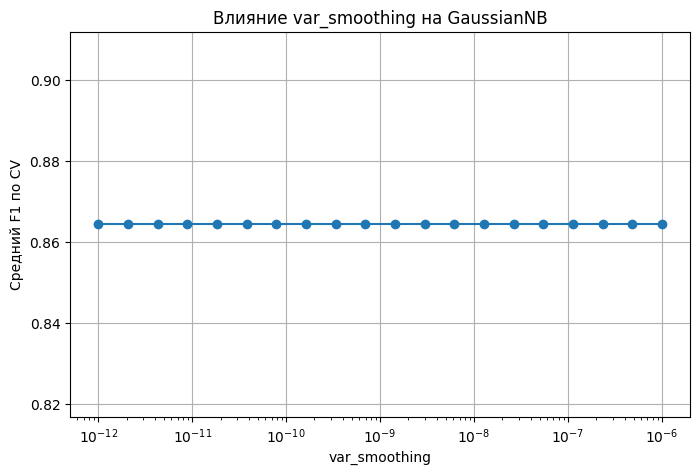

In [40]:
results_gnb = pd.DataFrame(grid_gnb.cv_results_)

plt.figure(figsize=(8, 5))

plt.semilogx(
    results_gnb["param_var_smoothing"].astype(float),
    results_gnb["mean_test_score"],
    marker="o"
)

plt.xlabel("var_smoothing")
plt.ylabel("Средний F1 по CV")
plt.title("Влияние var_smoothing на GaussianNB")

plt.grid()
plt.show()

MultinomialNB (основной параметр alpha)

In [41]:
from sklearn.naive_bayes import MultinomialNB

param_grid_mnb = {
    "alpha": [
        0.001,
        0.01,
        0.1,
        0.5,
        1,
        2,
        5,
        10
    ]
}

grid_mnb = GridSearchCV(
    estimator=MultinomialNB(),
    param_grid=param_grid_mnb,
    scoring="f1",
    cv=5,
    n_jobs=-1
)

grid_mnb.fit(X_train_minmax, y_train)

print("Лучшие параметры:", grid_mnb.best_params_)
print("Лучший F1 CV:", grid_mnb.best_score_)

results_tuned["MultinomialNB"] = evaluate_tuned_model(
    grid_mnb.best_estimator_,
    X_train_minmax,
    X_test_minmax,
    y_train,
    y_test
)

Лучшие параметры: {'alpha': 0.001}
Лучший F1 CV: 0.8699456484348126


График влияния alpha

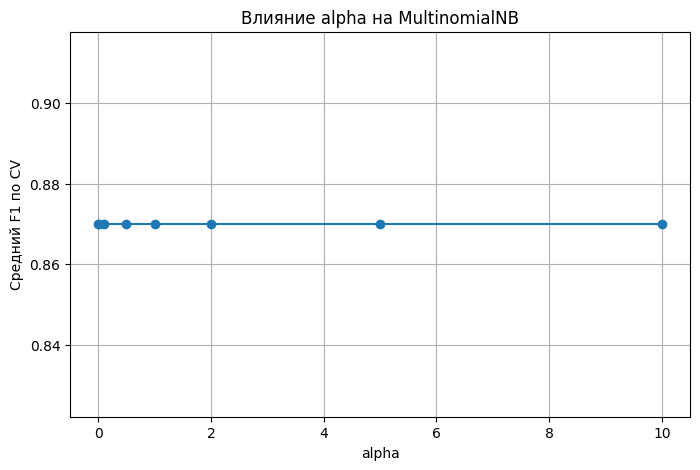

In [42]:
results_mnb = pd.DataFrame(grid_mnb.cv_results_)

plt.figure(figsize=(8, 5))

plt.plot(
    results_mnb["param_alpha"].astype(float),
    results_mnb["mean_test_score"],
    marker="o"
)

plt.xlabel("alpha")
plt.ylabel("Средний F1 по CV")
plt.title("Влияние alpha на MultinomialNB")

plt.grid()
plt.show()

ComplementNB (также alpha)

In [43]:
from sklearn.naive_bayes import ComplementNB

param_grid_cnb = {
    "alpha": [
        0.001,
        0.01,
        0.1,
        0.5,
        1,
        2,
        5,
        10
    ],
    
    "norm": [
        True,
        False
    ]
}

grid_cnb = GridSearchCV(
    estimator=ComplementNB(),
    param_grid=param_grid_cnb,
    scoring="f1",
    cv=5,
    n_jobs=-1
)

grid_cnb.fit(X_train_minmax, y_train)

print("Лучшие параметры:", grid_cnb.best_params_)
print("Лучший F1 CV:", grid_cnb.best_score_)

results_tuned["ComplementNB"] = evaluate_tuned_model(
    grid_cnb.best_estimator_,
    X_train_minmax,
    X_test_minmax,
    y_train,
    y_test
)

Лучшие параметры: {'alpha': 0.001, 'norm': True}
Лучший F1 CV: 0.8699456484348126


BernoulliNB (параметры alpha и binarize)

In [44]:
from sklearn.naive_bayes import BernoulliNB

param_grid_bnb = {
    "alpha": [
        0.001,
        0.01,
        0.1,
        0.5,
        1,
        2,
        5
    ],
    
    "binarize": [
        0.2,
        0.3,
        0.4,
        0.5,
        0.6,
        0.7,
        0.8
    ]
}

grid_bnb = GridSearchCV(
    estimator=BernoulliNB(),
    param_grid=param_grid_bnb,
    scoring="f1",
    cv=5,
    n_jobs=-1
)

grid_bnb.fit(X_train_minmax, y_train)

print("Лучшие параметры:", grid_bnb.best_params_)
print("Лучший F1 CV:", grid_bnb.best_score_)

results_tuned["BernoulliNB"] = evaluate_tuned_model(
    grid_bnb.best_estimator_,
    X_train_minmax,
    X_test_minmax,
    y_train,
    y_test
)

Лучшие параметры: {'alpha': 0.01, 'binarize': 0.5}
Лучший F1 CV: 0.8699456484348126


Вывод: изменение параметров сглаживания alpha и var_smoothing оказало незначительное влияние на качество большинства моделей. Наиболее заметное улучшение наблюдалось у ComplementNB: F1 увеличился с 0,8814 до 0,9032.

Decision Tree (наиболее важные параметры: criterion, max_depth, min_samples_split, min_samples_leaf)

In [45]:
from sklearn.tree import DecisionTreeClassifier

param_grid_tree = {
    "criterion": [
        "gini",
        "entropy",
        "log_loss"
    ],
    
    "max_depth": [
        None,
        2,
        3,
        4,
        5,
        6,
        8,
        10
    ],
    
    "min_samples_split": [
        2,
        5,
        10,
        20
    ],
    
    "min_samples_leaf": [
        1,
        2,
        5,
        10
    ]
}

grid_tree = GridSearchCV(
    estimator=DecisionTreeClassifier(
        random_state=42
    ),
    param_grid=param_grid_tree,
    scoring="f1",
    cv=5,
    n_jobs=-1
)

grid_tree.fit(X_train_standard, y_train)

print("Лучшие параметры:", grid_tree.best_params_)
print("Лучший F1 CV:", grid_tree.best_score_)

results_tuned["Decision Tree"] = evaluate_tuned_model(
    grid_tree.best_estimator_,
    X_train_standard,
    X_test_standard,
    y_train,
    y_test
)

Лучшие параметры: {'criterion': 'gini', 'max_depth': 2, 'min_samples_leaf': 10, 'min_samples_split': 2}
Лучший F1 CV: 0.8699456484348126


Отдельно, исследование влияния max_depth

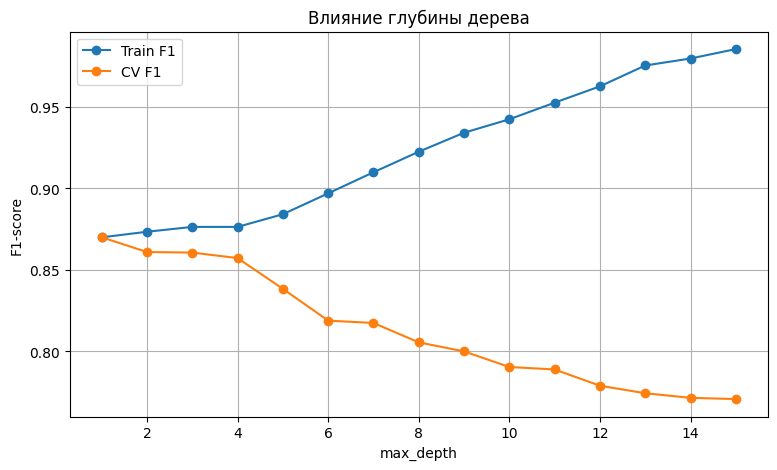

In [46]:
depths = range(1, 16)

train_scores = []
cv_scores = []

for depth in depths:
    
    model = DecisionTreeClassifier(
        max_depth=depth,
        random_state=42
    )
    
    model.fit(
        X_train_standard,
        y_train
    )
    
    train_pred = model.predict(
        X_train_standard
    )
    
    train_scores.append(
        f1_score(
            y_train,
            train_pred
        )
    )
    
    cv_score = cross_val_score(
        model,
        X_train_standard,
        y_train,
        cv=5,
        scoring="f1"
    ).mean()
    
    cv_scores.append(cv_score)

plt.figure(figsize=(9, 5))

plt.plot(
    depths,
    train_scores,
    marker="o",
    label="Train F1"
)

plt.plot(
    depths,
    cv_scores,
    marker="o",
    label="CV F1"
)

plt.xlabel("max_depth")
plt.ylabel("F1-score")
plt.title("Влияние глубины дерева")

plt.legend()
plt.grid()

plt.show()

Вывод: наибольшее улучшение среди всех алгоритмов достигнуто при ограничении глубины дерева до max_depth=2 и установке min_samples_leaf=10. F1 вырос с 0,8166 до 0,9032, что свидетельствует о снижении переобучения и улучшении обобщающей способности модели.

Linear Discriminant Analysis (параметры solver, shrinkage)

In [47]:
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.model_selection import GridSearchCV

param_grid_lda = [
    {
        "solver": ["svd"]
    },
    {
        "solver": ["lsqr"],
        "shrinkage": [
            None,
            "auto",
            0.1,
            0.3,
            0.5,
            0.7,
            0.9
        ]
    },
    {
        "solver": ["eigen"],
        "shrinkage": [
            "auto",
            0.1,
            0.3,
            0.5,
            0.7,
            0.9
        ]
    }
]

grid_lda = GridSearchCV(
    estimator=LinearDiscriminantAnalysis(),
    param_grid=param_grid_lda,
    scoring="f1",
    cv=5,
    n_jobs=-1,
    error_score=np.nan
)

grid_lda.fit(
    X_train_standard,
    y_train
)

print("Лучшие параметры:", grid_lda.best_params_)
print("Лучший F1 CV:", grid_lda.best_score_)

results_tuned["LDA"] = evaluate_tuned_model(
    grid_lda.best_estimator_,
    X_train_standard,
    X_test_standard,
    y_train,
    y_test
)

Лучшие параметры: {'shrinkage': 'auto', 'solver': 'lsqr'}
Лучший F1 CV: 0.8699456484348126


Вывод: оптимальными оказались solver='lsqr' и shrinkage='auto'. Однако качество классификации практически не изменилось: F1 остался равным 0,9081.

Support Vector Machine (основные параметры kernel, C, gamma, degree)

In [48]:
from sklearn.svm import SVC

param_grid_svm = [
    {
        "kernel": ["linear"],
        "C": [
            0.01,
            0.1,
            1,
            10,
            100
        ]
    },
    
    {
        "kernel": ["rbf"],
        "C": [
            0.01,
            0.1,
            1,
            10,
            100
        ],
        
        "gamma": [
            "scale",
            "auto",
            0.001,
            0.01,
            0.1,
            1
        ]
    },
    
    {
        "kernel": ["poly"],
        "C": [
            0.1,
            1,
            10
        ],
        
        "degree": [
            2,
            3,
            4
        ],
        
        "gamma": [
            "scale",
            "auto"
        ]
    }
]

grid_svm = GridSearchCV(
    estimator=SVC(
        probability=True,
        random_state=42
    ),
    param_grid=param_grid_svm,
    scoring="f1",
    cv=5,
    n_jobs=-1
)

grid_svm.fit(
    X_train_standard,
    y_train
)

print("Лучшие параметры:", grid_svm.best_params_)
print("Лучший F1 CV:", grid_svm.best_score_)

results_tuned["SVM"] = evaluate_tuned_model(
    grid_svm.best_estimator_,
    X_train_standard,
    X_test_standard,
    y_train,
    y_test
)

Лучшие параметры: {'C': 1, 'gamma': 0.01, 'kernel': 'rbf'}
Лучший F1 CV: 0.8702661207097441


И, отдельно влияние C для SVM

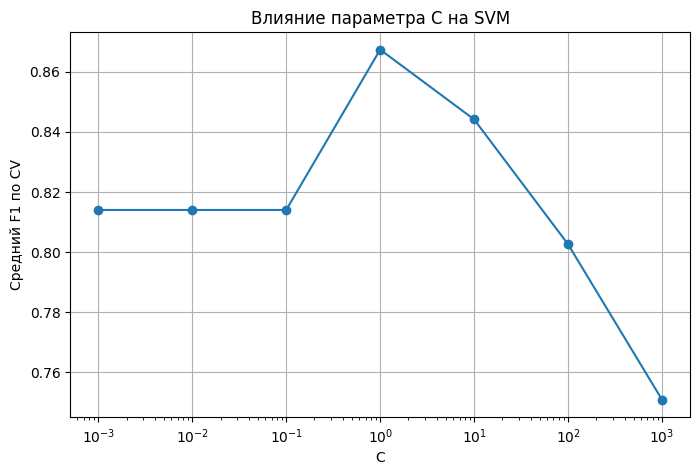

In [49]:
C_values = [
    0.001,
    0.01,
    0.1,
    1,
    10,
    100,
    1000
]

svm_scores = []

for C in C_values:
    
    model = SVC(
        C=C,
        kernel="rbf",
        gamma="scale"
    )
    
    score = cross_val_score(
        model,
        X_train_standard,
        y_train,
        cv=5,
        scoring="f1"
    ).mean()
    
    svm_scores.append(score)

plt.figure(figsize=(8, 5))

plt.semilogx(
    C_values,
    svm_scores,
    marker="o"
)

plt.xlabel("C")
plt.ylabel("Средний F1 по CV")
plt.title("Влияние параметра C на SVM")

plt.grid()
plt.show()

Вывод: наилучшие результаты получены с ядром rbf, C=1 и gamma=0.01. F1 увеличился с 0,8984 до 0,9032. Это показывает, что подбор параметров регуляризации и ядра способен немного повысить качество классификации.

k-Nearest Neighbors (основные параметры: n_neighbors, weights, metric, p)

In [50]:
from sklearn.neighbors import KNeighborsClassifier

param_grid_knn = {
    "n_neighbors": [
        3,
        5,
        7,
        9,
        11,
        13,
        15,
        17,
        19,
        21
    ],
    
    "weights": [
        "uniform",
        "distance"
    ],
    
    "metric": [
        "minkowski",
        "manhattan",
        "euclidean"
    ],
    
    "p": [
        1,
        2
    ]
}

grid_knn = GridSearchCV(
    estimator=KNeighborsClassifier(),
    param_grid=param_grid_knn,
    scoring="f1",
    cv=5,
    n_jobs=-1
)

grid_knn.fit(
    X_train_standard,
    y_train
)

print("Лучшие параметры:", grid_knn.best_params_)
print("Лучший F1 CV:", grid_knn.best_score_)

results_tuned["kNN"] = evaluate_tuned_model(
    grid_knn.best_estimator_,
    X_train_standard,
    X_test_standard,
    y_train,
    y_test
)

Лучшие параметры: {'metric': 'minkowski', 'n_neighbors': 21, 'p': 1, 'weights': 'distance'}
Лучший F1 CV: 0.8475499284607444


Исследование влияния числа соседей k

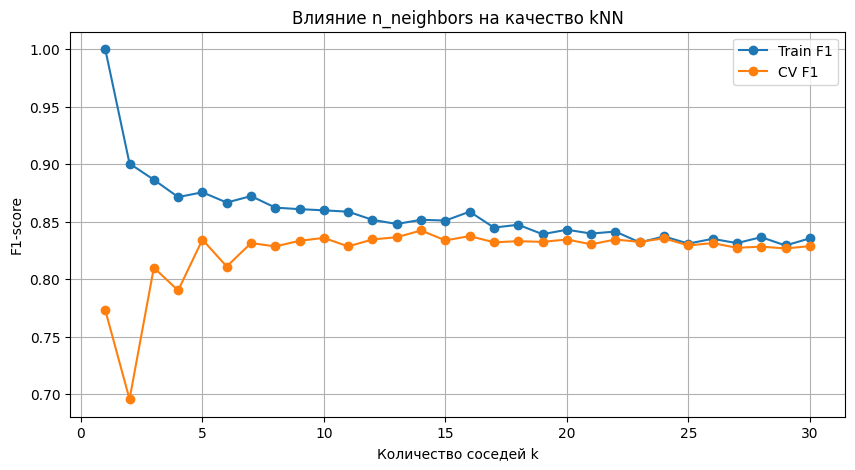

In [51]:
k_values = range(1, 31)

knn_train_scores = []
knn_cv_scores = []

for k in k_values:
    
    model = KNeighborsClassifier(
        n_neighbors=k
    )
    
    model.fit(
        X_train_standard,
        y_train
    )
    
    train_pred = model.predict(
        X_train_standard
    )
    
    knn_train_scores.append(
        f1_score(
            y_train,
            train_pred
        )
    )
    
    cv_score = cross_val_score(
        model,
        X_train_standard,
        y_train,
        cv=5,
        scoring="f1"
    ).mean()
    
    knn_cv_scores.append(cv_score)

plt.figure(figsize=(10, 5))

plt.plot(
    k_values,
    knn_train_scores,
    marker="o",
    label="Train F1"
)

plt.plot(
    k_values,
    knn_cv_scores,
    marker="o",
    label="CV F1"
)

plt.xlabel("Количество соседей k")
plt.ylabel("F1-score")
plt.title("Влияние n_neighbors на качество kNN")

plt.legend()
plt.grid()

plt.show()

Вывод: наилучшие результаты получены с ядром rbf, C=1 и gamma=0.01. F1 увеличился с 0,8984 до 0,9032. Это показывает, что подбор параметров регуляризации и ядра способен немного повысить качество классификации.

Итоговая таблица после настройки

In [52]:
tuned_results_df = pd.DataFrame(
    results_tuned
).T

tuned_results_df.round(4)

,Accuracy,Precision,Recall,F1,ROC-AUC
GaussianNB,0.8537,0.8384,0.9765,0.9022,0.8037
MultinomialNB,0.8537,0.8317,0.9882,0.9032,0.8548
ComplementNB,0.8537,0.8317,0.9882,0.9032,0.8502
BernoulliNB,0.8537,0.8384,0.9765,0.9022,0.8449
Decision Tree,0.8537,0.8317,0.9882,0.9032,0.7633
LDA,0.8618,0.8400,0.9882,0.9081,0.8477
SVM,0.8537,0.8317,0.9882,0.9032,0.8226
kNN,0.8211,0.8058,0.9765,0.8830,0.8223


Сравнение до и после настройки

In [53]:
baseline_comparison = results_df.copy()
baseline_comparison["Тип"] = "До настройки"

tuned_comparison = tuned_results_df.copy()
tuned_comparison["Тип"] = "После настройки"

comparison_df = pd.concat([
    baseline_comparison,
    tuned_comparison
])

comparison_df

,Accuracy,Precision,Recall,F1,ROC-AUC,Тип
GaussianNB,0.853659,0.838384,0.976471,0.902174,0.803715,До настройки
MultinomialNB,0.853659,0.831683,0.988235,0.903226,0.854180,До настройки
ComplementNB,0.829268,0.847826,0.917647,0.881356,0.854180,До настройки
BernoulliNB,0.853659,0.838384,0.976471,0.902174,0.845820,До настройки
Decision Tree,0.747967,0.821429,0.811765,0.816568,0.708514,До настройки
LDA,0.861789,0.840000,0.988235,0.908108,0.847059,До настройки
SVM,0.845528,0.823529,0.988235,0.898396,0.820124,До настройки
kNN,0.821138,0.805825,0.976471,0.882979,0.785759,До настройки
GaussianNB,0.853659,0.838384,0.976471,0.902174,0.803715,После настройки
MultinomialNB,0.853659,0.831683,0.988235,0.903226,0.854799,После настройки


И, конкретно F1 до и после настройки

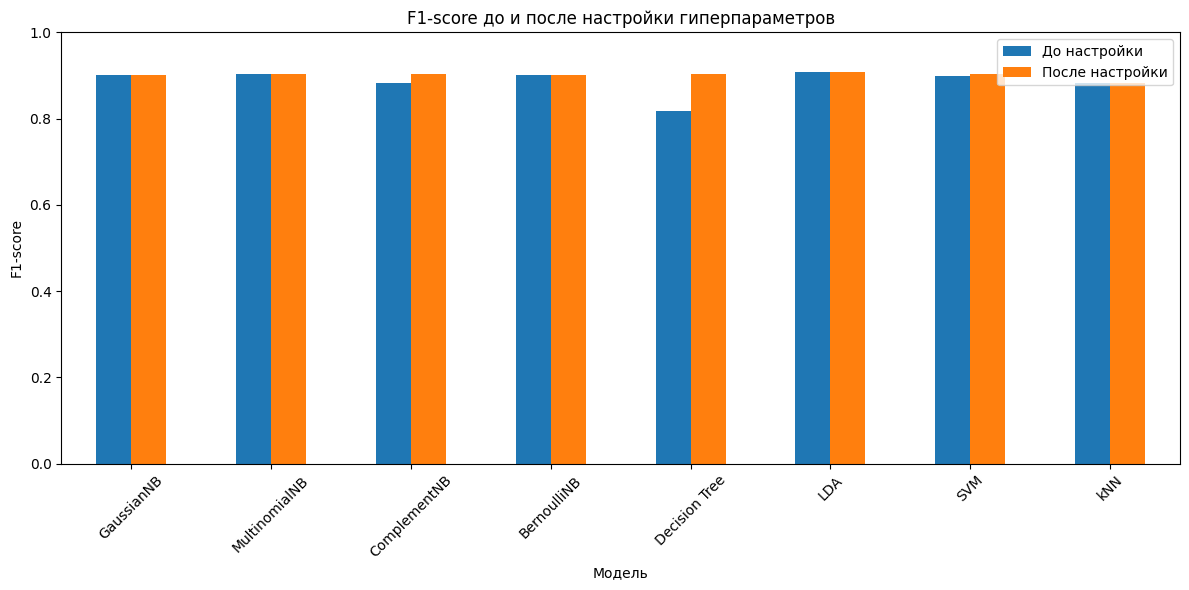

In [54]:
comparison_f1 = pd.DataFrame({
    "До настройки": results_df["F1"],
    "После настройки": tuned_results_df["F1"]
})

comparison_f1.round(4)

#график
comparison_f1.plot(
    kind="bar",
    figsize=(12, 6)
)

plt.ylabel("F1-score")
plt.xlabel("Модель")
plt.title("F1-score до и после настройки гиперпараметров")

plt.ylim(0, 1)
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

Вывод: настройка гиперпараметров положительно повлияла на качество отдельных классификаторов, особенно Decision Tree и ComplementNB. При этом некоторые алгоритмы продемонстрировали устойчивость к изменению параметров. Наилучший итоговый результат по F1-score показал Linear Discriminant Analysis (F1 = 0,9081, Accuracy = 0,8618).

6. Нейронная сеть на TensorFlow

Архитектура нейронной сети:

Для данной задачи используем MLP (Multi-Layer Perception). Начальная архитектура базовой модели состоит из двух скрытых стлоёв и одного выходного нейрона.

Используемые компоненты:

- Input - Принимает подготовленные признаки
- Dense(32) - Первый скрытый полносвязный слой из 32 нейронов
- Dense (16) - Второй скрытый полносвязный слой из 16 нейронов
- ReLU - Нелинейная функция активации скрытых слоев
- Dense (1, sigmoid) - Выходной нейрон, выдает вероятность одобрения кредита
- Binary Cross-Entropy - Вычисляет ошибку бинарной классификации
- Adam - Оптимизирует веса сети

Функции активации:

ReLU - позволяет сети моделировать нелинейные зависимости. f(x)=max(0,x)

Sigmoid - преобразует выход нейрона в значение от 0 до 1, которое интерпретируется как вероятность положительного класса. sigma(x)=1/1+e^{-x}

Функция потерь: Binary Cross-Entropy

Оптимизатор: Adam - адаптивно обновляет веса с учетом оценок первого и второго моментов градиента. Начальная скорость обучения = learning_rate=0.001

Установка TensorFlow через терминал

Проверка

In [55]:
import tensorflow as tf

print(tf.__version__)

2.21.0


Импорт библиотек

In [56]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import clone


from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    RocCurveDisplay
)

from pathlib import Path
from datetime import datetime
keras.utils.set_random_seed(42)

Подготовка данных для нейронной сети

Ранее мы уже разделяли данные на выборки:
- X_train, X_test, y_train, y_test;
- preprocessor_standard;
- X_train_standard, X_test_standard.

Для исследования гиперпараметров разделяем обучающую выборку ещё на две части. Это нужно, чтобы не использовать тестовую выборку при выборе архитектуры. Важно: чтобы не допустить утечки информации, заново обучаем preprocessing только на X_nn_train и затем применяем его к validation.

In [57]:
#разбиение

X_nn_train, X_nn_val, y_nn_train, y_nn_val = train_test_split(
    X_train,
    y_train,
    test_size=0.2,
    random_state=42,
    stratify=y_train
)

nn_preprocessor = clone(preprocessor_standard)

X_nn_train_scaled = nn_preprocessor.fit_transform(X_nn_train)
X_nn_val_scaled = nn_preprocessor.transform(X_nn_val)

X_nn_train_scaled = np.asarray(
    X_nn_train_scaled, dtype=np.float32
)

X_nn_val_scaled = np.asarray(
    X_nn_val_scaled, dtype=np.float32
)

y_nn_train = np.asarray(y_nn_train, dtype=np.float32)
y_nn_val = np.asarray(y_nn_val, dtype=np.float32)

input_dim = X_nn_train_scaled.shape[1]

print("Train:", X_nn_train_scaled.shape)
print("Validation:", X_nn_val_scaled.shape)
print("Количество признаков:", input_dim)

Train: (392, 18)
Validation: (99, 18)
Количество признаков: 18


Здесь float32 используется потому, что это стандартный и экономичный числовой тип для вычислений TensorFlow.

Создание базовой нейронной сети

Создадим функцию, которая позволит впоследствии менять архитектуру и активации без переписывания кода.

In [58]:
def create_nn(
    hidden_layers=(32, 16),
    activation="relu",
    learning_rate=0.001
):
    model = keras.Sequential(name="Loan_Approval_MLP")

    model.add(
        layers.Input(shape=(input_dim,))
    )

    for units in hidden_layers:
        model.add(
            layers.Dense(
                units=units,
                activation=activation
            )
        )

    model.add(
        layers.Dense(1, activation="sigmoid")
    )

    model.compile(
        optimizer=keras.optimizers.Adam(
            learning_rate=learning_rate
        ),
        loss="binary_crossentropy",
        metrics=[
            keras.metrics.BinaryAccuracy(name="accuracy"),
            keras.metrics.Precision(name="precision"),
            keras.metrics.Recall(name="recall"),
            keras.metrics.AUC(name="auc")
        ]
    )

    return model

Создадим baseline. summary() покажет архитектуру, размерность каждого слоя и число обучаемых параметров.

In [59]:
keras.backend.clear_session()
keras.utils.set_random_seed(42)

baseline_nn = create_nn(
    hidden_layers=(32, 16),
    activation="relu",
    learning_rate=0.001
)

baseline_nn.summary()

Model: "Loan_Approval_MLP"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 32)             │           608 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,153 (4.50 KB)

 Trainable params: 1,153 (4.50 KB)

 Non-trainable params: 0 (0.00 B)

Обучение базовой модели. Используем 50 эпох и размер батча 32.

In [60]:
from pathlib import Path
from datetime import datetime

LOG_ROOT = (
    Path("C:/tensorboard_logs/loan_nn")
    / datetime.now().strftime("%Y%m%d_%H%M%S_%f")
)

baseline_log_dir = LOG_ROOT / "baseline"

baseline_tb = keras.callbacks.TensorBoard(
    log_dir=str(baseline_log_dir),
    histogram_freq=1,
    update_freq="epoch"
)

print("TensorBoard:", baseline_tb.log_dir)

TensorBoard: C:\tensorboard_logs\loan_nn\20261111_122632_581380\baseline


In [61]:
history_baseline = baseline_nn.fit(
    X_nn_train_scaled,
    y_nn_train,
    validation_data=(
        X_nn_val_scaled,
        y_nn_val
    ),
    epochs=50,
    batch_size=32,
    callbacks=[baseline_tb],
    verbose=1
)

Epoch 1/50
13/13 ━━━━━━━━━━━━━━━━━━━━ 2s 42ms/step - accuracy: 0.5842 - auc: 0.6260 - loss: 0.6929 - precision: 0.7819 - recall: 0.5465 - val_accuracy: 0.6566 - val_auc: 0.6179 - val_loss: 0.6423 - val_precision: 0.7500 - val_recall: 0.7500
Epoch 2/50
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.7041 - auc: 0.6637 - loss: 0.6214 - precision: 0.7492 - recall: 0.8550 - val_accuracy: 0.7071 - val_auc: 0.6112 - val_loss: 0.6080 - val_precision: 0.7241 - val_recall: 0.9265
Epoch 3/50
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.7143 - auc: 0.6915 - loss: 0.5858 - precision: 0.7275 - recall: 0.9331 - val_accuracy: 0.7374 - val_auc: 0.6305 - val_loss: 0.5904 - val_precision: 0.7333 - val_recall: 0.9706
Epoch 4/50
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.7270 - auc: 0.7175 - loss: 0.5653 - precision: 0.7275 - recall: 0.9628 - val_accuracy: 0.7475 - val_auc: 0.6516 - val_loss: 0.5786 - val_precision: 0.7363 - val_recall: 0.9853
Epoch 5/50
13/13 ━━━━━━━━━━━━━━━━━━━━

In [62]:
from pathlib import Path

print("Путь к журналам:", baseline_log_dir)
print("Папка существует:", baseline_log_dir.exists())

# Ищем все файлы событий во вложенных папках
event_files = list(
    baseline_log_dir.rglob("events.out.tfevents.*")
)

print("Количество файлов TensorBoard:", len(event_files))

for file in event_files:
    print(file)

Путь к журналам: C:\tensorboard_logs\loan_nn\20261111_122632_581380\baseline
Папка существует: True
Количество файлов TensorBoard: 2
C:\tensorboard_logs\loan_nn\20261111_122632_581380\baseline\train\events.out.tfevents.1794374792.ELENAZHUKOVA.22676.0.v2
C:\tensorboard_logs\loan_nn\20261111_122632_581380\baseline\validation\events.out.tfevents.1794374793.ELENAZHUKOVA.22676.1.v2


По выводу можно увидеть что обучение работает и метрики рассчитываются на обеих выборках.

Функция для автоматического построения четырех графиков: Loss, Accuracy, Precision и Recall.

In [63]:
def plot_training_history(history, title="Neural Network"):

    metrics = [
        ("loss", "Loss"),
        ("accuracy", "Accuracy"),
        ("precision", "Precision"),
        ("recall", "Recall")
    ]

    fig, axes = plt.subplots(2, 2, figsize=(13, 9))

    for ax, (metric, label) in zip(axes.flat, metrics):

        ax.plot(
            history.history[metric],
            label="Train",
            linewidth=2
        )

        ax.plot(
            history.history[f"val_{metric}"],
            label="Validation",
            linewidth=2
        )

        ax.set_title(label)
        ax.set_xlabel("Epoch")
        ax.set_ylabel(label)
        ax.grid(alpha=0.3)
        ax.legend()

    fig.suptitle(title, fontsize=15)

    plt.tight_layout()
    plt.show()

Вывод графика:

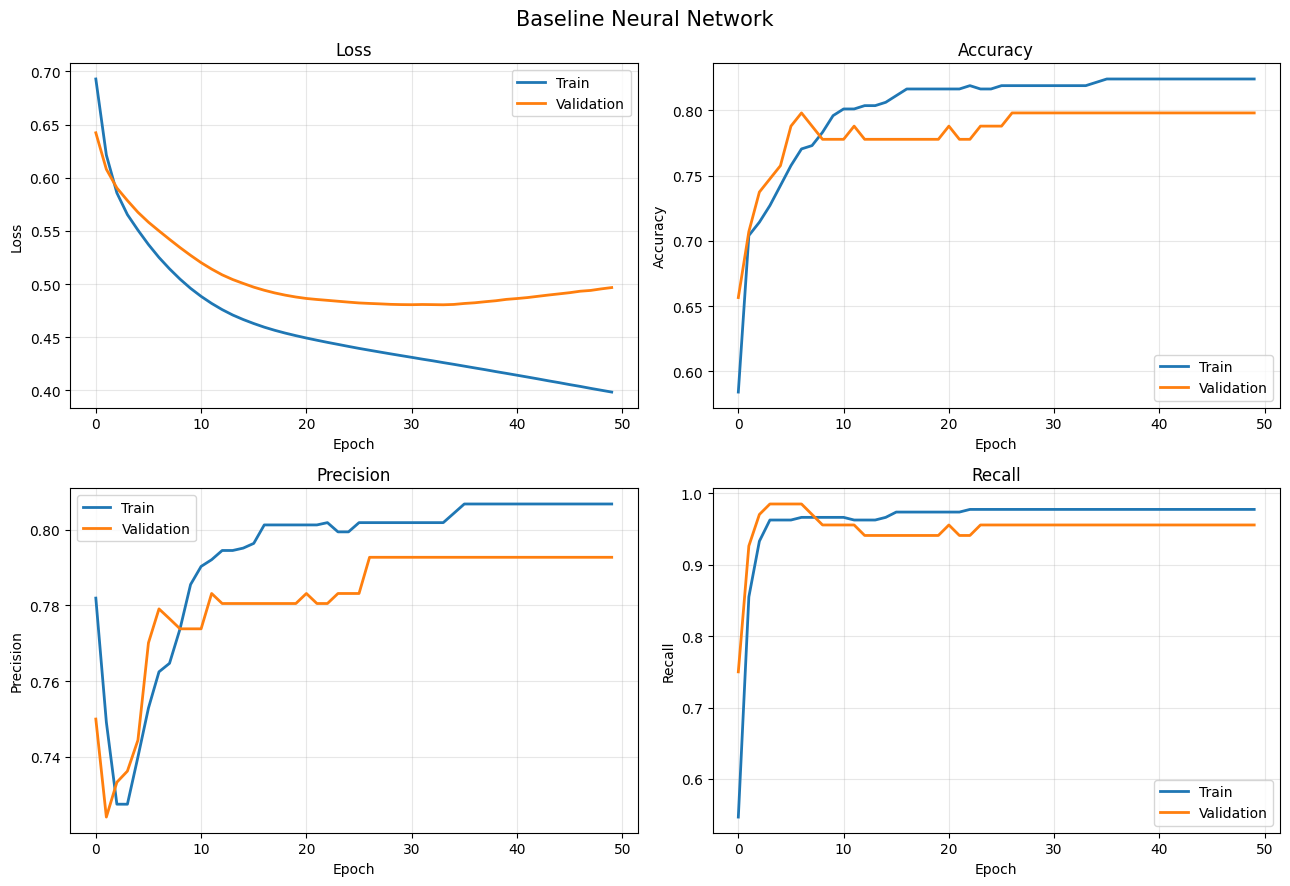

In [64]:
plot_training_history(
    history_baseline,
    "Baseline Neural Network"
)

Нейронная сеть быстро обучается и достигает стабильных показателей качества примерно к 25–30-й эпохе. Дальнейшее обучение практически не улучшает Accuracy, Precision и Recall, но сопровождается увеличением валидационной ошибки, что указывает на начальное переобучение. Высокий Recall при более низком Precision может свидетельствовать о склонности модели предсказывать положительный класс.

Мониторинг обучения через TensorBoard

Загрузка расширения и запуск панели

In [65]:
from tensorboard.backend.event_processing import event_accumulator

train_log_dir = baseline_log_dir / "train"

ea = event_accumulator.EventAccumulator(
    str(train_log_dir)
)

ea.Reload()

print("Доступные теги TensorBoard:")
print(ea.Tags())

Доступные теги TensorBoard:
{'images': [], 'audio': [], 'histograms': [], 'scalars': [], 'distributions': [], 'tensors': ['keras', 'epoch_accuracy', 'epoch_auc', 'epoch_loss', 'epoch_precision', 'epoch_recall', 'epoch_learning_rate', 'kernel/histogram', 'bias/histogram'], 'graph': False, 'meta_graph': False, 'run_metadata': []}


In [66]:
%load_ext tensorboard

TensorBoard был запущен через терминал с помощью комманды python -m tensorboard.main --logdir "C:\tensorboard_logs\loan_nn" --port 6010

Исследование гиперпараметров нейронной сети

Исследуемые параметры:

1. Количество эпох (epochs).
2. Размер батча (batch_size).
3. Количество скрытых слоев.
4. Количество нейронов в слоях.
5. Функции активации (relu, tanh, sigmoid, elu).

Установка начального состояния и создание правильного пути

In [72]:
keras.utils.set_random_seed(42)

# Корневая директория, которую читает TensorBoard
TB_ROOT = Path(r"C:\tensorboard_logs\loan_nn")

# Отдельная папка для текущего исследования
RUN_ROOT = TB_ROOT / (
    "hyperparameter_study_"
    + datetime.now().strftime("%Y%m%d_%H%M%S_%f")
)

RUN_ROOT.mkdir(parents=True, exist_ok=True)

print("Корневая папка:", TB_ROOT)
print("Папка экспериментов:", RUN_ROOT)
print("Директория существует:", RUN_ROOT.is_dir())

Корневая папка: C:\tensorboard_logs\loan_nn
Папка экспериментов: C:\tensorboard_logs\loan_nn\hyperparameter_study_20261111_144731_374697
Директория существует: True


Разделение тестовой выборки на обучающую и валидационную части. Преобразуем признаки, обучая стандартизацию только на X_nn_train.

In [73]:
X_nn_train, X_nn_val, y_nn_train, y_nn_val = train_test_split(
    X_train,
    y_train,
    test_size=0.2,
    random_state=42,
    stratify=y_train
)

nn_preprocessor = clone(preprocessor_standard)

X_nn_train_scaled = nn_preprocessor.fit_transform(X_nn_train)
X_nn_val_scaled = nn_preprocessor.transform(X_nn_val)

X_nn_train_scaled = np.asarray(
    X_nn_train_scaled, dtype=np.float32
)

X_nn_val_scaled = np.asarray(
    X_nn_val_scaled, dtype=np.float32
)

y_nn_train = np.asarray(y_nn_train, dtype=np.float32)
y_nn_val = np.asarray(y_nn_val, dtype=np.float32)

input_dim = X_nn_train_scaled.shape[1]

print("Train:", X_nn_train_scaled.shape)
print("Validation:", X_nn_val_scaled.shape)
print("Количество признаков:", input_dim)

Train: (392, 18)
Validation: (99, 18)
Количество признаков: 18


Callback для гарантированной записи метрик

Вместо использования стандартного keras.callbacks.TensorBoard, создаём собственный callback на основе tf.summary. Он будет записывать все необходимые метрики по эпохам в отдельные файлы событий для train и validation.

In [74]:
class MetricsTensorBoard(keras.callbacks.Callback):

    def __init__(self, log_dir):
        super().__init__()

        self.log_dir = Path(log_dir)

        self.train_dir = self.log_dir / "train"
        self.val_dir = self.log_dir / "validation"

        self.train_dir.mkdir(
            parents=True,
            exist_ok=True
        )

        self.val_dir.mkdir(
            parents=True,
            exist_ok=True
        )

        self.train_writer = tf.summary.create_file_writer(
            str(self.train_dir)
        )

        self.val_writer = tf.summary.create_file_writer(
            str(self.val_dir)
        )

    def on_epoch_end(self, epoch, logs=None):

        logs = logs or {}
        step = epoch + 1

        for metric in [
            "loss",
            "accuracy",
            "precision",
            "recall",
            "auc"
        ]:

            # Train
            if metric in logs:
                with self.train_writer.as_default():
                    tf.summary.scalar(
                        metric,
                        logs[metric],
                        step=step
                    )

            # Validation
            val_metric = f"val_{metric}"

            if val_metric in logs:
                with self.val_writer.as_default():
                    tf.summary.scalar(
                        metric,
                        logs[val_metric],
                        step=step
                    )

        # Записываем данные после каждой эпохи
        self.train_writer.flush()
        self.val_writer.flush()

    def on_train_end(self, logs=None):

        self.train_writer.flush()
        self.val_writer.flush()

        self.train_writer.close()
        self.val_writer.close()

Функция создания нейронной сети

In [75]:
def create_nn(
    input_dim,
    hidden_layers=(32, 16),
    activation="relu",
    learning_rate=0.001
):

    model = keras.Sequential()

    model.add(
        layers.Input(shape=(input_dim,))
    )

    for units in hidden_layers:

        model.add(
            layers.Dense(
                units=units,
                activation=activation
            )
        )

    model.add(
        layers.Dense(
            units=1,
            activation="sigmoid"
        )
    )

    model.compile(
        optimizer=keras.optimizers.Adam(
            learning_rate=learning_rate
        ),

        loss="binary_crossentropy",

        metrics=[
            keras.metrics.BinaryAccuracy(
                name="accuracy"
            ),
            keras.metrics.Precision(
                name="precision"
            ),
            keras.metrics.Recall(
                name="recall"
            ),
            keras.metrics.AUC(
                name="auc"
            )
        ]
    )

    return model

Универсальная функция эксперимента

1. Создаёт новую модель с заданными гиперпараметрами.
2. Обучает ее.
3. Записывает метрики каждой эпохи в TensorBoard.
4. Сохраняет историю обучения.
5. Рассчитывает Accuracy, Precision, Recall, F1 и ROC-AUC на validation.
6. Возвращает результаты для построения сравнительных графиков.

In [76]:
experiment_results = []
experiment_histories = {}
experiment_configs = {}

def run_experiment(
    name,
    hidden_layers=(32, 16),
    activation="relu",
    epochs=50,
    batch_size=32,
    learning_rate=0.001
):

    # Очищаем предыдущий граф
    keras.backend.clear_session()

    # Фиксируем случайность
    keras.utils.set_random_seed(42)

    # Создаем модель
    model = create_nn(
        input_dim=input_dim,
        hidden_layers=hidden_layers,
        activation=activation,
        learning_rate=learning_rate
    )

    # Папка текущего эксперимента
    experiment_dir = RUN_ROOT / name

    # Callback TensorBoard
    tb_callback = MetricsTensorBoard(
        log_dir=experiment_dir
    )

    # Обучение
    history = model.fit(
        X_nn_train_scaled,
        y_nn_train,

        validation_data=(
            X_nn_val_scaled,
            y_nn_val
        ),

        epochs=epochs,
        batch_size=batch_size,

        callbacks=[tb_callback],

        verbose=0
    )

    # Вероятности на validation
    y_prob = model.predict(
        X_nn_val_scaled,
        verbose=0
    ).ravel()

    y_pred = (y_prob >= 0.5).astype(int)

    # Метрики
    result = {
        "Experiment": name,
        "Layers": str(hidden_layers),
        "Activation": activation,
        "Epochs": epochs,
        "Batch size": batch_size,

        "Accuracy": accuracy_score(
            y_nn_val, y_pred
        ),

        "Precision": precision_score(
            y_nn_val, y_pred,
            zero_division=0
        ),

        "Recall": recall_score(
            y_nn_val, y_pred,
            zero_division=0
        ),

        "F1": f1_score(
            y_nn_val, y_pred,
            zero_division=0
        ),

        "ROC-AUC": roc_auc_score(
            y_nn_val, y_prob
        ),

        "Best val_loss": min(
            history.history["val_loss"]
        ),

        "Best epoch": int(
            np.argmin(history.history["val_loss"]) + 1
        )
    }

    # Сохраняем результаты
    experiment_results.append(result)
    experiment_histories[name] = history

    experiment_configs[name] = {
        "hidden_layers": hidden_layers,
        "activation": activation,
        "epochs": epochs,
        "batch_size": batch_size,
        "learning_rate": learning_rate
    }

    print(
        f"{name}: "
        f"F1={result['F1']:.4f}, "
        f"ROC-AUC={result['ROC-AUC']:.4f}, "
        f"Best epoch={result['Best epoch']}"
    )

    return result

Базовый эксперемент - обучение с двумя скрытыми слоями, 50 эпохами и батчем 32.

In [77]:
baseline_result = run_experiment(
    name="baseline",
    hidden_layers=(32, 16),
    activation="relu",
    epochs=50,
    batch_size=32
)


baseline: F1=0.8667, ROC-AUC=0.7415, Best epoch=34


Общая функция для отображения Loss, Accuracy, Precision, Recall и AUC

In [79]:
def plot_training_history(history, title):

    metrics = [
        "loss",
        "accuracy",
        "precision",
        "recall",
        "auc"
    ]

    fig, axes = plt.subplots(
        3, 2,
        figsize=(13, 13)
    )

    for ax, metric in zip(axes.flat, metrics):

        train_values = history.history[metric]
        val_values = history.history[f"val_{metric}"]

        epochs = range(1, len(train_values) + 1)

        ax.plot(
            epochs,
            train_values,
            label="Train",
            linewidth=2
        )

        ax.plot(
            epochs,
            val_values,
            label="Validation",
            linewidth=2
        )

        ax.set_xlabel("Epoch")
        ax.set_ylabel(metric)
        ax.set_title(metric.upper())

        ax.legend()
        ax.grid(alpha=0.3)

    # Удаляем пустой шестой график
    fig.delaxes(axes.flat[-1])

    fig.suptitle(title, fontsize=15)

    plt.tight_layout()
    plt.show()

Графики базовой модели

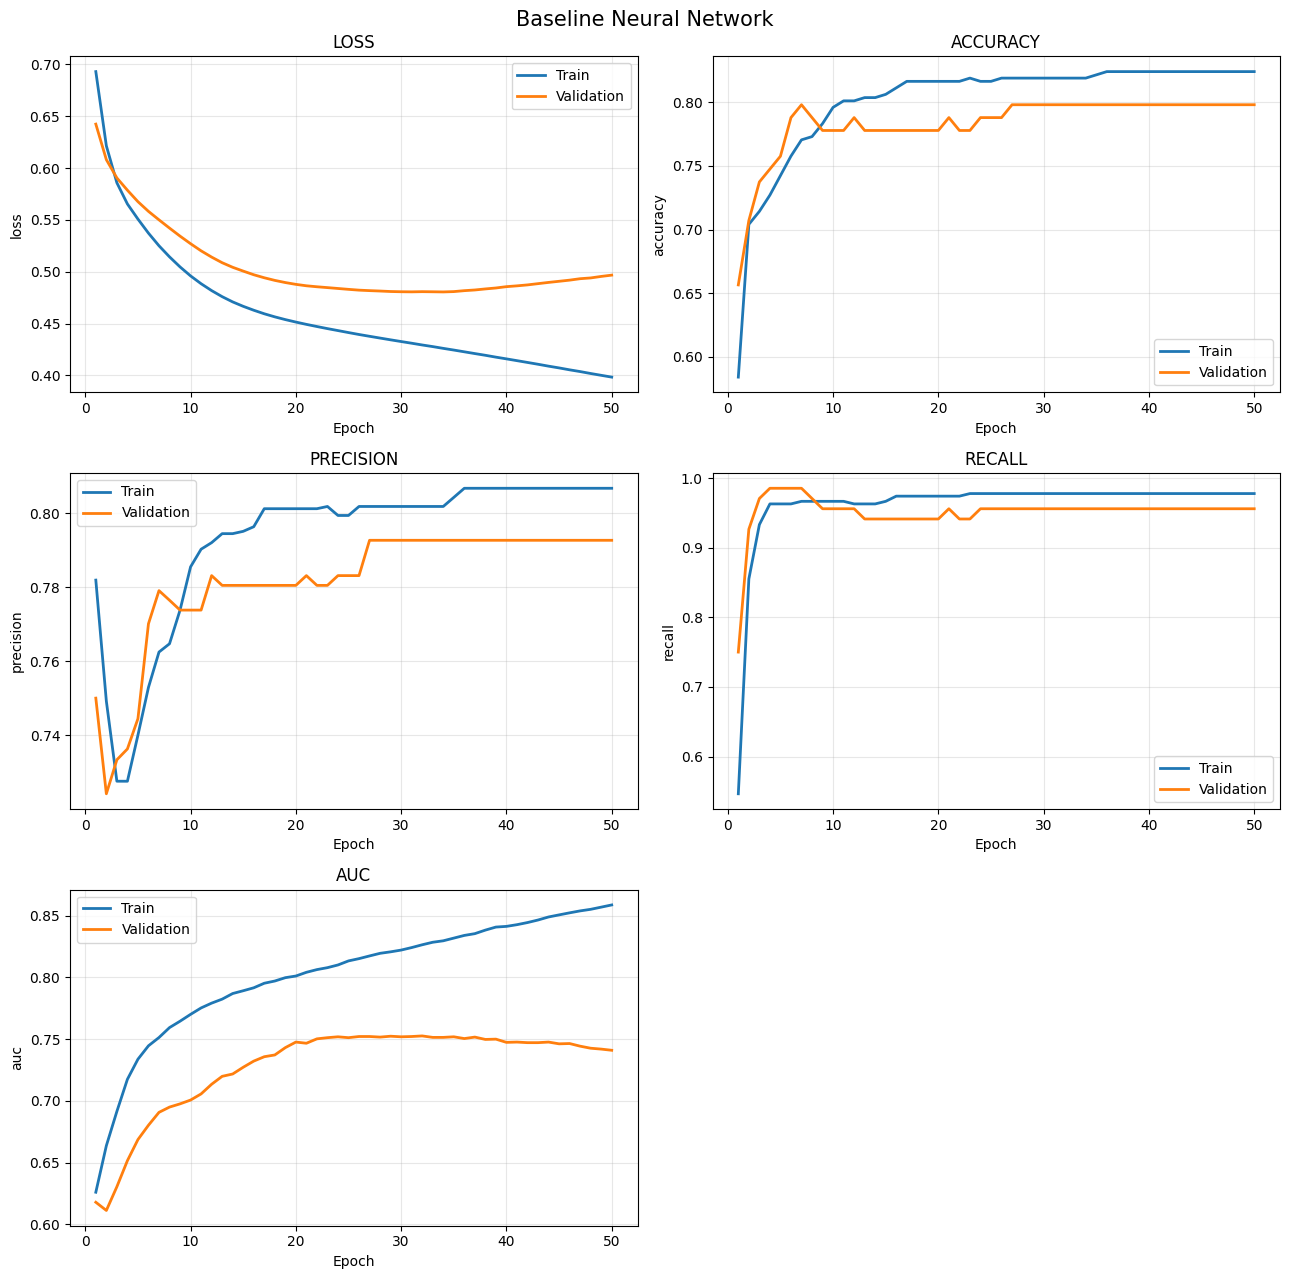

In [80]:
plot_training_history(
    experiment_histories["baseline"],
    "Baseline Neural Network"
)

Вывод: Базовая нейронная сеть демонстрирует быстрое улучшение качества в первые 20–30 эпох, после чего валидационные метрики выходят на плато или начинают ухудшаться. Наиболее выраженные признаки переобучения наблюдаются на графиках Loss и AUC.

Высокий Recall (96%) при сравнительно низком Precision (79%) свидетельствует о склонности модели относить объекты к положительному классу, что может быть связано с дисбалансом классов в датасете.

Оптимальная продолжительность обучения составляет приблизительно 25–30 эпох, однако конкретную точку остановки следует выбирать по контролируемой метрике. Для предотвращения переобучения рекомендуется использовать EarlyStopping с мониторингом val_loss и восстановлением лучших весов модели.

Эксперимент №1 - исследование количества эпох. Проверка 20, 50 и 100 эпох

In [81]:
epoch_values = [20, 50, 100]

epoch_results = []

for epochs in epoch_values:

    result = run_experiment(
        name=f"epochs_{epochs}",
        hidden_layers=(32, 16),
        activation="relu",
        epochs=epochs,
        batch_size=32
    )

    epoch_results.append(result)

epoch_df = pd.DataFrame(epoch_results)

display(epoch_df.round(4))

epochs_20: F1=0.8533, ROC-AUC=0.7453, Best epoch=20
epochs_50: F1=0.8667, ROC-AUC=0.7415, Best epoch=34
epochs_100: F1=0.8276, ROC-AUC=0.7149, Best epoch=34


,Experiment,Layers,Activation,Epochs,Batch size,Accuracy,Precision,Recall,F1,ROC-AUC,Best val_loss,Best epoch
0,epochs_20,"(32, 16)",relu,20,32,0.7778,0.7805,0.9412,0.8533,0.7453,0.4878,20
1,epochs_50,"(32, 16)",relu,50,32,0.7980,0.7927,0.9559,0.8667,0.7415,0.4805,34
2,epochs_100,"(32, 16)",relu,100,32,0.7475,0.7792,0.8824,0.8276,0.7149,0.4805,34


График влияния количества эпох на F1-score

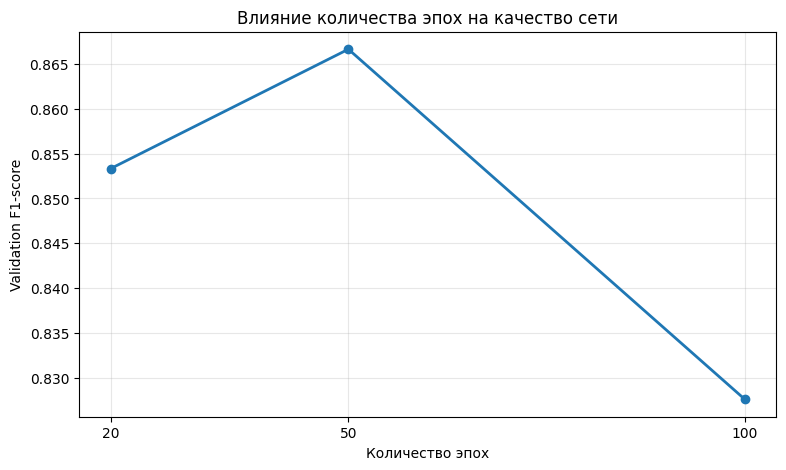

In [82]:
plt.figure(figsize=(9, 5))

plt.plot(
    epoch_df["Epochs"],
    epoch_df["F1"],
    marker="o",
    linewidth=2
)

plt.xlabel("Количество эпох")
plt.ylabel("Validation F1-score")
plt.title("Влияние количества эпох на качество сети")

plt.xticks(epoch_values)
plt.grid(alpha=0.3)

plt.show()

Оптимальным среди исследованных значений является 50 эпох, при которых достигается максимальный F1-score (0,867). Увеличение количества эпох до 100 не улучшает качество классификации, а, напротив, снижает его. Это может быть связано с переобучением нейронной сети.

Сравнение кривых обучения и валидации

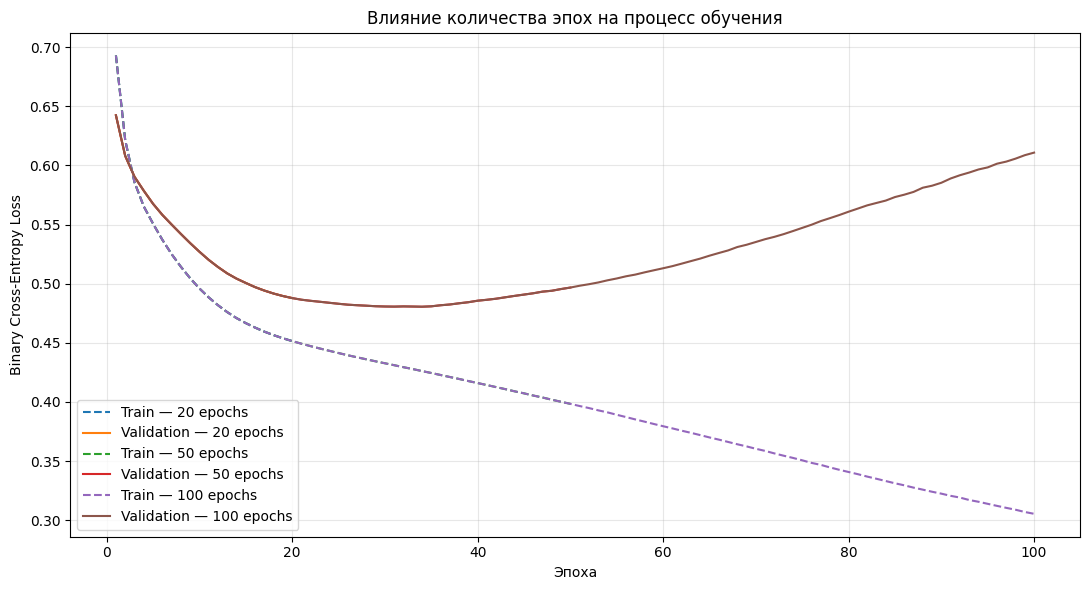

In [83]:
plt.figure(figsize=(11, 6))

for epochs in epoch_values:

    history = experiment_histories[f"epochs_{epochs}"]

    epoch_range = range(
        1,
        len(history.history["loss"]) + 1
    )

    plt.plot(
        epoch_range,
        history.history["loss"],
        linestyle="--",
        label=f"Train — {epochs} epochs"
    )

    plt.plot(
        epoch_range,
        history.history["val_loss"],
        label=f"Validation — {epochs} epochs"
    )

plt.xlabel("Эпоха")
plt.ylabel("Binary Cross-Entropy Loss")
plt.title("Влияние количества эпох на процесс обучения")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Вывод: оптимальная продолжительность обучения по минимуму валидационной ошибки составляет примерно 25–30 эпох. Дальнейшее увеличение количества эпох приводит к переобучению и ухудшению обобщающей способности нейронной сети.

Эксперимент №2 — исследование Batch Size. Значения 8, 16, 32 и 64.

In [84]:
batch_values = [8, 16, 32, 64]

batch_results = []

for batch_size in batch_values:

    result = run_experiment(
        name=f"batch_{batch_size}",
        hidden_layers=(32, 16),
        activation="relu",
        epochs=50,
        batch_size=batch_size
    )

    batch_results.append(result)

batch_df = pd.DataFrame(batch_results)

display(batch_df.round(4))

batch_8: F1=0.8435, ROC-AUC=0.7177, Best epoch=16
batch_16: F1=0.8435, ROC-AUC=0.7343, Best epoch=20
batch_32: F1=0.8667, ROC-AUC=0.7415, Best epoch=34
batch_64: F1=0.8591, ROC-AUC=0.7576, Best epoch=46


,Experiment,Layers,Activation,Epochs,Batch size,Accuracy,Precision,Recall,F1,ROC-AUC,Best val_loss,Best epoch
0,batch_8,"(32, 16)",relu,50,8,0.7677,0.7848,0.9118,0.8435,0.7177,0.4762,16
1,batch_16,"(32, 16)",relu,50,16,0.7677,0.7848,0.9118,0.8435,0.7343,0.4797,20
2,batch_32,"(32, 16)",relu,50,32,0.7980,0.7927,0.9559,0.8667,0.7415,0.4805,34
3,batch_64,"(32, 16)",relu,50,64,0.7879,0.7901,0.9412,0.8591,0.7576,0.4866,46


График зависимости F1 от Batch Size

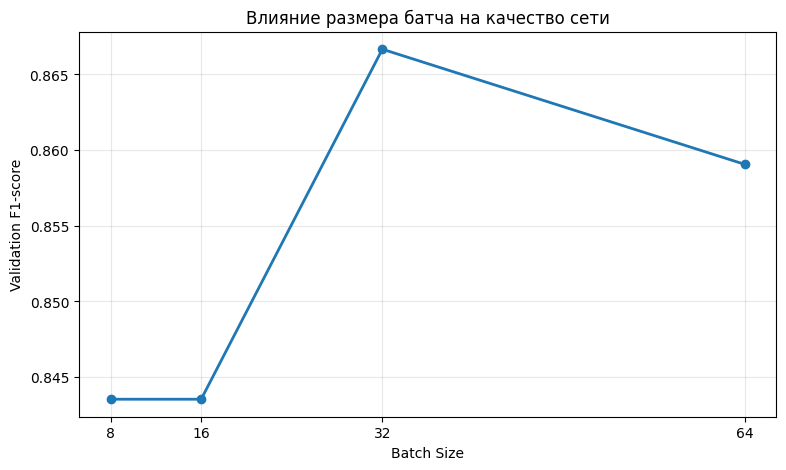

In [85]:
plt.figure(figsize=(9, 5))

plt.plot(
    batch_df["Batch size"],
    batch_df["F1"],
    marker="o",
    linewidth=2
)

plt.xlabel("Batch Size")
plt.ylabel("Validation F1-score")
plt.title("Влияние размера батча на качество сети")

plt.xticks(batch_values)
plt.grid(alpha=0.3)

plt.show()

Вывод: оптимальным среди исследованных значений является размер батча 32, обеспечивающий наилучшее качество классификации. Меньшие батчи могут приводить к более шумным обновлениям весов, а большие — к менее частым обновлениям за эпоху.

Сравнение обучения для разных батчей

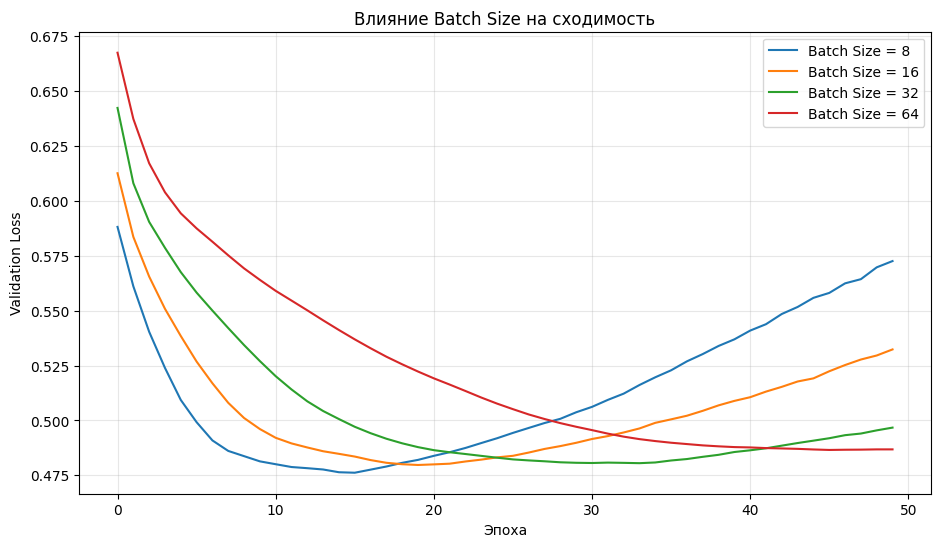

In [86]:
plt.figure(figsize=(11, 6))

for batch_size in batch_values:

    history = experiment_histories[
        f"batch_{batch_size}"
    ]

    plt.plot(
        history.history["val_loss"],
        label=f"Batch Size = {batch_size}"
    )

plt.xlabel("Эпоха")
plt.ylabel("Validation Loss")
plt.title("Влияние Batch Size на сходимость")

plt.legend()
plt.grid(alpha=0.3)
plt.show()

Вывод: маленькие батчи обеспечивают более быстрое снижение ошибки, но переобучение начинается раньше. Большие батчи приводят к более медленной, но стабильной сходимости. Batch Size = 32 является наиболее сбалансированным вариантом, обеспечивающим стабильное обучение и наилучший F1-score среди исследованных размеров батча.

Эксперимент №3 — исследование количества слоев и нейронов. 5 разных архитектур.

In [87]:
architectures = [
    (16,),
    (32,),
    (32, 16),
    (64, 32),
    (64, 32, 16)
]

architecture_results = []

for architecture in architectures:

    name = "architecture_" + "_".join(
        map(str, architecture)
    )

    result = run_experiment(
        name=name,
        hidden_layers=architecture,
        activation="relu",
        epochs=50,
        batch_size=32
    )

    architecture_results.append(result)

architecture_df = pd.DataFrame(
    architecture_results
)

display(architecture_df.round(4))

architecture_16: F1=0.8627, ROC-AUC=0.7258, Best epoch=50
architecture_32: F1=0.8627, ROC-AUC=0.7177, Best epoch=45
architecture_32_16: F1=0.8667, ROC-AUC=0.7415, Best epoch=34
architecture_64_32: F1=0.8414, ROC-AUC=0.7291, Best epoch=14
architecture_64_32_16: F1=0.8356, ROC-AUC=0.7301, Best epoch=14


,Experiment,Layers,Activation,Epochs,Batch size,Accuracy,Precision,Recall,F1,ROC-AUC,Best val_loss,Best epoch
0,architecture_16,"(16,)",relu,50,32,0.7879,0.7765,0.9706,0.8627,0.7258,0.4947,50
1,architecture_32,"(32,)",relu,50,32,0.7879,0.7765,0.9706,0.8627,0.7177,0.5030,45
2,architecture_32_16,"(32, 16)",relu,50,32,0.7980,0.7927,0.9559,0.8667,0.7415,0.4805,34
3,architecture_64_32,"(64, 32)",relu,50,32,0.7677,0.7922,0.8971,0.8414,0.7291,0.4835,14
4,architecture_64_32_16,"(64, 32, 16)",relu,50,32,0.7576,0.7821,0.8971,0.8356,0.7301,0.4854,14


График влияния архитектуры на F1-score

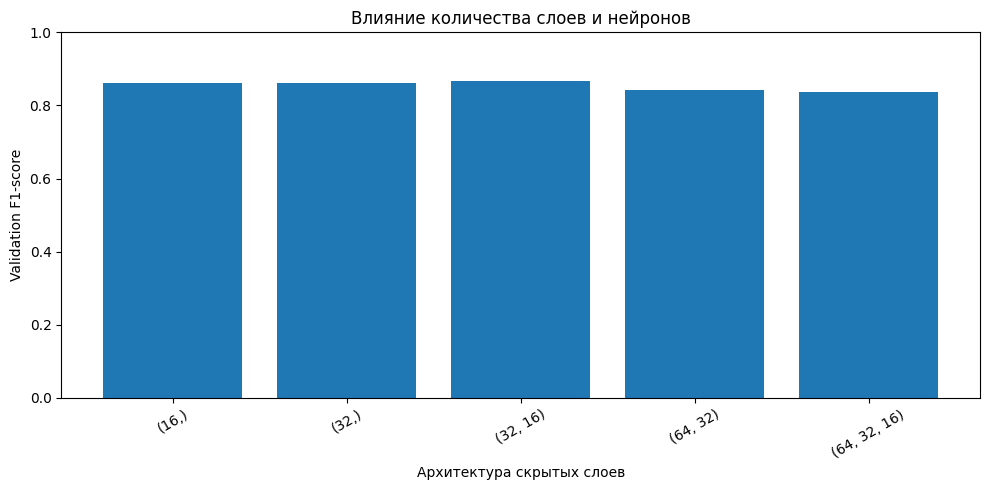

In [88]:
plt.figure(figsize=(10, 5))

plt.bar(
    architecture_df["Layers"],
    architecture_df["F1"]
)

plt.xlabel("Архитектура скрытых слоев")
plt.ylabel("Validation F1-score")
plt.title("Влияние количества слоев и нейронов")

plt.ylim(0, 1)
plt.xticks(rotation=30)
plt.tight_layout()

plt.show()

Вывод: оптимальной среди исследованных архитектур является сеть с двумя скрытыми слоями (32 и 16 нейронов). Дальнейшее усложнение архитектуры не улучшает качество классификации, а может приводить к переобучению или затруднять оптимизацию.

График Validation Loss для разных архитектур

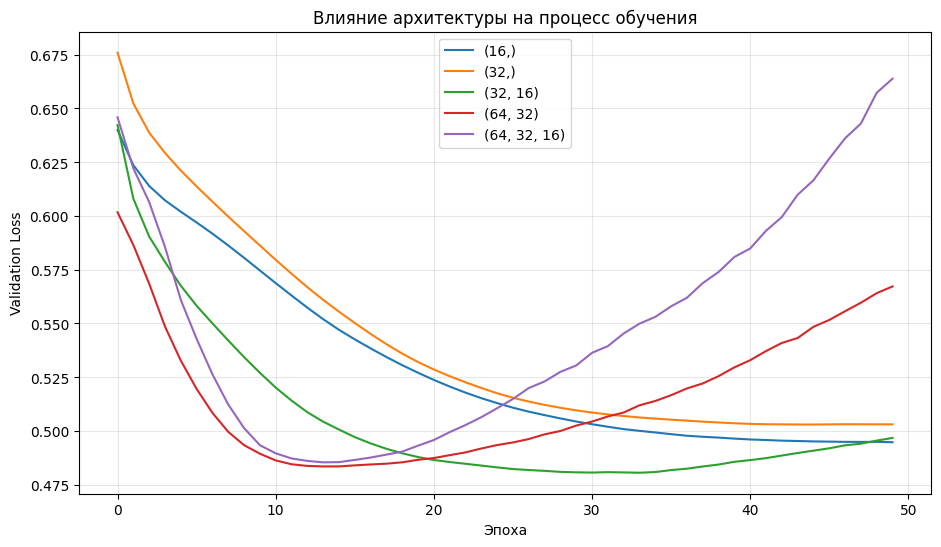

In [89]:
plt.figure(figsize=(11, 6))

for architecture in architectures:

    name = "architecture_" + "_".join(
        map(str, architecture)
    )

    history = experiment_histories[name]

    plt.plot(
        history.history["val_loss"],
        label=str(architecture)
    )

plt.xlabel("Эпоха")
plt.ylabel("Validation Loss")
plt.title("Влияние архитектуры на процесс обучения")

plt.legend()
plt.grid(alpha=0.3)
plt.show()

Вывод: увеличение количества слоёв и нейронов ускоряет первоначальное снижение ошибки, однако повышает риск переобучения. Оптимальной среди исследованных архитектур является (32, 16), обеспечивающая низкую валидационную ошибку и наилучший F1-score по предыдущему эксперименту.

Эксперимент №4 — исследование функций активации. 4 функции: relu, tanh, sigmoid, elu.

In [90]:
activations = [
    "relu",
    "tanh",
    "sigmoid",
    "elu"
]

activation_results = []

for activation in activations:

    result = run_experiment(
        name=f"activation_{activation}",
        hidden_layers=(32, 16),
        activation=activation,
        epochs=50,
        batch_size=32
    )

    activation_results.append(result)

activation_df = pd.DataFrame(
    activation_results
)

display(activation_df.round(4))

activation_relu: F1=0.8667, ROC-AUC=0.7415, Best epoch=34
activation_tanh: F1=0.8553, ROC-AUC=0.7438, Best epoch=40
activation_sigmoid: F1=0.8701, ROC-AUC=0.6988, Best epoch=50
activation_elu: F1=0.8533, ROC-AUC=0.7495, Best epoch=50


,Experiment,Layers,Activation,Epochs,Batch size,Accuracy,Precision,Recall,F1,ROC-AUC,Best val_loss,Best epoch
0,activation_relu,"(32, 16)",relu,50,32,0.7980,0.7927,0.9559,0.8667,0.7415,0.4805,34
1,activation_tanh,"(32, 16)",tanh,50,32,0.7778,0.7738,0.9559,0.8553,0.7438,0.4855,40
2,activation_sigmoid,"(32, 16)",sigmoid,50,32,0.7980,0.7791,0.9853,0.8701,0.6988,0.5242,50
3,activation_elu,"(32, 16)",elu,50,32,0.7778,0.7805,0.9412,0.8533,0.7495,0.4793,50


Сравнение функций активации по F1

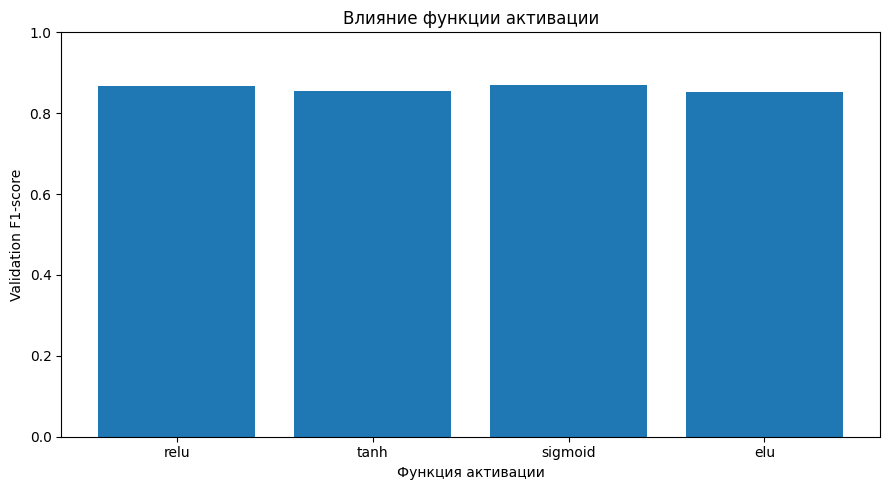

In [91]:
plt.figure(figsize=(9, 5))

plt.bar(
    activation_df["Activation"],
    activation_df["F1"]
)

plt.xlabel("Функция активации")
plt.ylabel("Validation F1-score")
plt.title("Влияние функции активации")

plt.ylim(0, 1)
plt.tight_layout()

plt.show()

Вывод: все функции активации обеспечивают сопоставимое качество классификации (F1-score ≈ 0,85–0,87). Sigmoid показывает наилучший результат, однако её преимущество перед ReLU незначительно.

Графики обучения для разных активаций

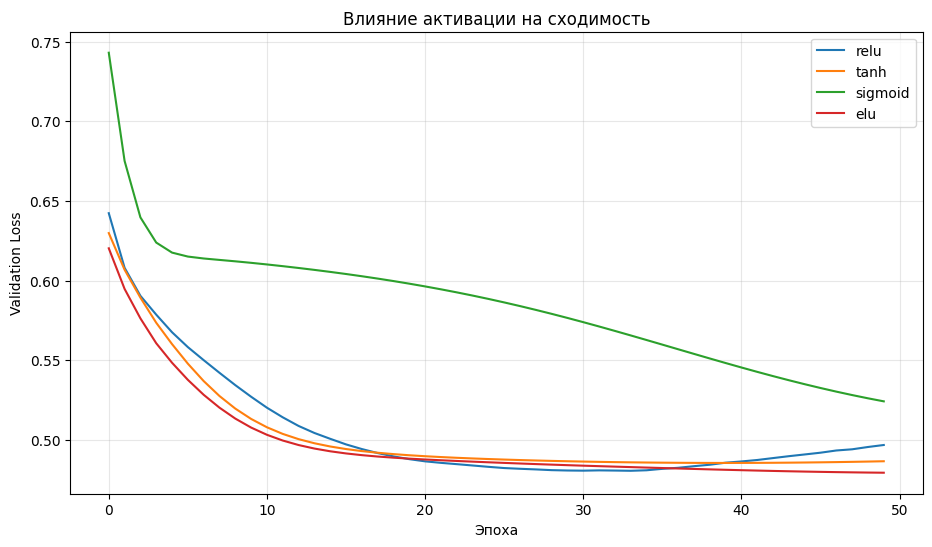

In [92]:
plt.figure(figsize=(11, 6))

for activation in activations:

    history = experiment_histories[
        f"activation_{activation}"
    ]

    plt.plot(
        history.history["val_loss"],
        label=activation
    )

plt.xlabel("Эпоха")
plt.ylabel("Validation Loss")
plt.title("Влияние активации на сходимость")

plt.legend()
plt.grid(alpha=0.3)
plt.show()

Вывод: наиболее быструю и стабильную сходимость демонстрирует ELU, тогда как Sigmoid обучается значительно медленнее. Несмотря на то что Sigmoid показала наибольший F1-score в предыдущем эксперименте, по скорости сходимости и величине валидационной ошибки она уступает остальным функциям

Итоговое сравнение всех экспериментов в общей таблице

In [93]:
all_nn_results = pd.DataFrame(
    experiment_results
)

display(
    all_nn_results.sort_values(
        by="F1",
        ascending=False
    ).round(4)
)

,Experiment,Layers,Activation,Epochs,Batch size,Accuracy,Precision,Recall,F1,ROC-AUC,Best val_loss,Best epoch
15,activation_sigmoid,"(32, 16)",sigmoid,50,32,0.7980,0.7791,0.9853,0.8701,0.6988,0.5242,50
0,baseline,"(32, 16)",relu,50,32,0.7980,0.7927,0.9559,0.8667,0.7415,0.4805,34
2,epochs_50,"(32, 16)",relu,50,32,0.7980,0.7927,0.9559,0.8667,0.7415,0.4805,34
10,architecture_32_16,"(32, 16)",relu,50,32,0.7980,0.7927,0.9559,0.8667,0.7415,0.4805,34
6,batch_32,"(32, 16)",relu,50,32,0.7980,0.7927,0.9559,0.8667,0.7415,0.4805,34
13,activation_relu,"(32, 16)",relu,50,32,0.7980,0.7927,0.9559,0.8667,0.7415,0.4805,34
9,architecture_32,"(32,)",relu,50,32,0.7879,0.7765,0.9706,0.8627,0.7177,0.5030,45
8,architecture_16,"(16,)",relu,50,32,0.7879,0.7765,0.9706,0.8627,0.7258,0.4947,50
7,batch_64,"(32, 16)",relu,50,64,0.7879,0.7901,0.9412,0.8591,0.7576,0.4866,46
14,activation_tanh,"(32, 16)",tanh,50,32,0.7778,0.7738,0.9559,0.8553,0.7438,0.4855,40


График F1-score всех экспериментов

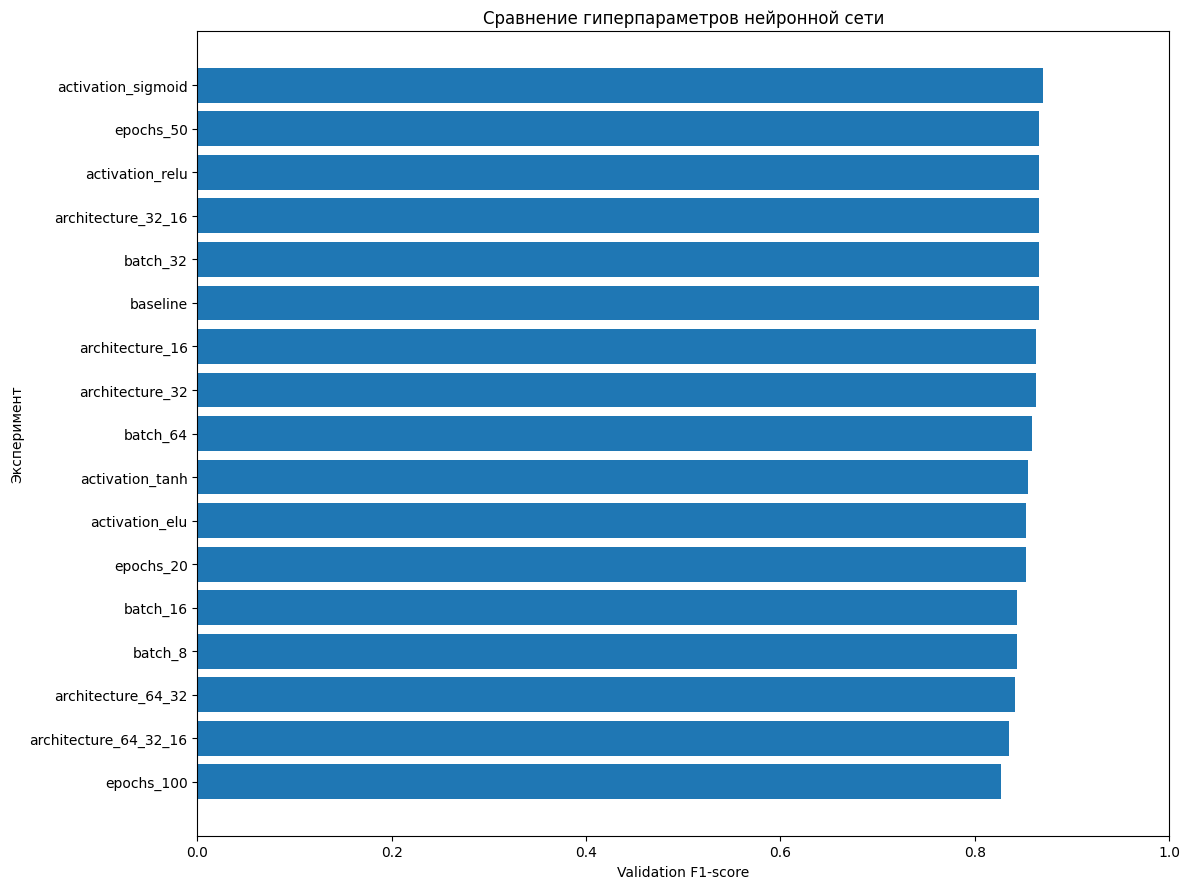

In [94]:
sorted_results = all_nn_results.sort_values(
    "F1"
)

plt.figure(figsize=(12, 9))

plt.barh(
    sorted_results["Experiment"],
    sorted_results["F1"]
)

plt.xlabel("Validation F1-score")
plt.ylabel("Эксперимент")
plt.title("Сравнение гиперпараметров нейронной сети")

plt.xlim(0, 1)
plt.tight_layout()
plt.show()

7. Сравнительный анализ качества методов классификации

В ходе лабораторной работы были исследованы пять методов классификации: наивный байесовский классификатор (GaussianNB, MultinomialNB, ComplementNB, BernoulliNB), дерево решений (Decision Tree), линейный дискриминантный анализ (LDA), метод опорных векторов (SVM) и метод ближайших соседей (kNN). Дополнительно была реализована и исследована полносвязная нейронная сеть на основе TensorFlow/Keras.

Качество моделей оценивалось с использованием метрик Accuracy, Precision, Recall, F1-score и ROC-AUC. Для классических алгоритмов была проведена настройка гиперпараметров с применением GridSearchCV и пятикратной кросс-валидации.

По результатам тестирования наиболее высокое качество продемонстрировал метод линейного дискриминантного анализа (LDA). После настройки гиперпараметров модель достигла Accuracy = 0.8618, Precision = 0.8400, Recall = 0.9882, F1-score = 0.9081 и ROC-AUC = 0.8477. Полученные значения свидетельствуют о высокой способности модели распознавать положительный класс при сравнительно небольшом количестве ошибок классификации.

Сопоставимые результаты были получены для байесовских классификаторов и SVM. Наибольшее значение ROC-AUC, равное 0.8548, показал MultinomialNB. Это свидетельствует о его хорошей способности ранжировать объекты по вероятности принадлежности к положительному классу.

Наиболее существенное улучшение после настройки гиперпараметров наблюдалось у дерева решений: Accuracy увеличилась с 0.7480 до 0.8537, а F1-score — с 0.8166 до 0.9032. Однако значение ROC-AUC осталось относительно низким и составило 0.7633.

Метод kNN продемонстрировал более низкое качество по сравнению с большинством остальных классификаторов: Accuracy = 0.8211, F1-score = 0.8830.

Для нейронной сети TensorFlow были исследованы количество эпох, размер батча, количество скрытых слоев и нейронов, а также функции активации. Наилучший валидационный F1-score составил 0.8701 при использовании функции sigmoid в скрытых слоях. При этом увеличение сложности сети и количества эпох не обеспечивало устойчивого улучшения качества. Для окончательного сравнения нейронной сети с классическими алгоритмами требуется оценка выбранной конфигурации на общей тестовой выборке.

Таким образом, среди классификаторов с полученными тестовыми результатами наиболее подходящим методом для рассматриваемого датасета является LDA, поскольку он обеспечивает наилучшее сочетание Accuracy, Precision, Recall и F1-score при относительно невысокой вычислительной сложности. Однако различия между ведущими алгоритмами невелики, поэтому для подтверждения устойчивости результатов целесообразно использовать повторную стратифицированную кросс-валидацию.